# Can we trust the realtime decoder? Offline as ground truth

**Purpose.** Find posterior-max thresholds under which the realtime decoder's output can be trusted, as candidate
conditions for future closed-loop optogenetics. Ground truth is the **offline decoder** (`decode_hex_any`). Rate and
latency are deliberately left out for now.

**Run:** Toby · 2025-03-16 · session 07 · `r4_merged_random_no_preload` (no preloaded encoder; random-walk prior,
movement_var 1; no barriers given to the decoder).

**Definitions used throughout**

| term | meaning |
|---|---|
| **threshold** | keep only bins whose realtime posterior max (`post_max`) is ≥ the threshold |
| **agree** | realtime's decoded hex is within `AGREE_TOL` = 1 hex step of offline's decoded hex |
| **non-local** | decoded position more than **20 cm** from the rat's tracked position (one hex step ≈ 13 cm, so this is "2+ hexes away"). Realtime's position = the centre of its decoded hex in cm; offline uses its own continuous decoded position |
| **non-local event** | the definition in `~/Desktop/continuous_fragmented_replay_fetching.ipynb`, applied to both decoders: a stretch of non-local samples lasting > 20 ms, split wherever the decode jumps > 20 cm; pieces that hold still ≥ 20 ms are **dwell** events (the main unit here), the whole stretches are **parent intervals** |
| **event agrees** | a realtime event overlaps an offline event in time *and*, in the overlapping bins, realtime is within 1 hex of offline at least half the time |
| **event passes the threshold** | the event's **mean** posterior max is ≥ the threshold |
| **running / still** | rat speed > 10 cm/s / < 2 cm/s (offline tracking) |

**Two kinds of score**, with offline as the reference:

- **precision**: of what realtime reports (bins, non-local bins, events) *and keeps at this threshold*, the share that
  matches offline;
- **recall**: of what offline reports, the share that realtime recovers (kept *and* matching).

**Error bars** are 95% block-bootstrap CIs (the session cut into 30 s chunks, whole chunks resampled 500×).

**Caveat.** Offline is an acausal smoother: it sees the future, realtime cannot. "Agreement with offline" is the
best available reference, not the truth about what the brain represented.

---
## Summary

Offline is the reference throughout; "agree" = realtime within 1 hex of offline.

1. **Posterior max works for local decoding.** Agreement rises from 43% (no threshold) to 62% at ≥ 0.3, 70% at ≥ 0.5
   and 78% at ≥ 0.9. Running bins sit 15–20 points above still bins at every threshold, and the cost is coverage:
   ≥ 0.5 keeps 18% of bins. (§3)
2. **It does not work for non-local content.** Realtime calls 55% of bins non-local (offline: 12%). Of its kept
   non-local bins, only 6% agree with offline with no threshold and 14% at ≥ 0.9, and it recovers at most 18% of
   offline's non-local bins. (§4)
3. **The same holds for non-local events.** Realtime produces ~10× more dwell events than offline (439 vs 42 a minute).
   Event precision climbs from 4% to about 20% only at thresholds that keep almost no events, and recall is at most 13%
   (about 20% at rest). (§5)
4. **Part of the still-bin disagreement is the reference's own uncertainty.** Where offline itself is least confident,
   agreement at rest is 17% and barely improves with a threshold. Non-local precision is low in every offline-confidence
   third, though, so that problem isn't reference noise. (§6)
5. **These threshold → agreement numbers carry over to unseen data.** Measured on half the session and checked on the
   other half, running bins match within about 1 point; still bins come out 3–5 points better, inside the CIs. (§7)
6. **Where realtime points matters as much as how sure it is.** Decodes of hexes 2, 49 and 4 agree 73–92% of the time;
   hex 17 (closed all epoch) and 22 almost never do, whatever the threshold. (§8)
7. **Other online signals help a lot for local decoding, a little for non-local.** Without using the rat's own
   position, a trust score from posterior shape, decode stability and speed keeps 88% agreement in its top 20% of bins
   (posterior max: 70%). On non-local bins the best score reaches 27% agreement in its top 5% (posterior max: 11%). (§9)
8. **Threshold menu (chosen on half the session, checked on the other half):** running ≥ 70% agreement at
   **≥ 0.34** (keeps 42%), running ≥ 80% at **≥ 0.64** (keeps 11%); still ≥ 60% at **≥ 0.48** (keeps 16%), still ≥ 70%
   at **≥ 0.82** (keeps 5%). No threshold gets non-local precision to 20%. (§10)
9. **Realtime has about 4.5× more non-local representation than offline, and its timing barely matches.** It is
   non-local in 55% of bins (offline: 12%). Firing on every realtime non-local stretch would mean 187 triggers a
   minute, covering about 45% of the session, and only 19% of those triggers would overlap an offline non-local
   stretch (17% by chance). A threshold of 0.5 cuts it to 4 a minute with 28% overlap. (§11)
   With a looser rule (one confident realtime non-local bin inside the offline stretch is enough), realtime reaches
   offline's non-local *place* in 24% of offline's stretches at ≥ 0.5, about 3× chance. As single-bin triggers,
   though, more than 90% of those bins would still be wrong. (§11b)
   The 3 minutes after each barrier shift look the same as the rest of the session. (§11c)


## 0 · Setup

In [1]:
import collections, glob, os, sys, warnings
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import yaml
from matplotlib.patches import RegularPolygon
from scipy.stats import rankdata

REPO = '/home/andy-quach/realtime_decoder'
sys.path.insert(0, REPO)
from realtime_decoder import transitions

# fixed colour roles (colour-blind-safe set, as in online_offline_comparison.ipynb)
RT, OF, TRUE = '#2b5c9e', '#d0663a', '#3c9a7b'           # realtime / offline / rat's true position
STILL_C, RUN_C = '#b3a9d9', '#5a4a9c'                    # behavioural state: light = still, dark = running
INK, INK2, MUTED, SHADE = '#222222', '#555555', '#8c8c8c', '#eeeeee'
OF_RAMP = ['#eba580', '#d9743f', '#a9471d']              # offline confidence: light = least, dark = most
CM_SEQ = mpl.colors.LinearSegmentedColormap.from_list(
    'mako_soft', sns.color_palette('mako_r', as_cmap=True)(np.linspace(0, 0.78, 256)))

plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Liberation Sans', 'Arial', 'Helvetica', 'DejaVu Sans'],
    'font.size': 9, 'axes.titlesize': 9.5, 'axes.labelsize': 9, 'legend.fontsize': 8,
    'xtick.labelsize': 8, 'ytick.labelsize': 8, 'mathtext.default': 'regular',
    'text.color': INK, 'axes.labelcolor': INK, 'axes.edgecolor': INK, 'xtick.color': INK, 'ytick.color': INK,
    'axes.linewidth': 0.8, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': False,
    'axes.titlelocation': 'left', 'axes.titlepad': 7,
    'xtick.direction': 'out', 'ytick.direction': 'out',
    'xtick.major.size': 3.5, 'ytick.major.size': 3.5, 'xtick.major.width': 0.8, 'ytick.major.width': 0.8,
    'lines.linewidth': 1.5, 'lines.markersize': 4, 'lines.solid_capstyle': 'round', 'patch.linewidth': 0,
    'legend.frameon': False, 'legend.handlelength': 1.6, 'legend.borderaxespad': 0.2,
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white',
    'figure.dpi': 120, 'savefig.dpi': 300, 'savefig.bbox': 'tight',
    'figure.constrained_layout.use': True,
    'pdf.fonttype': 42, 'ps.fonttype': 42, 'svg.fonttype': 'none',
})
pd.set_option('display.precision', 3)
PLAIN = mpl.ticker.FuncFormatter(lambda v, _: f'{v:g}')       # log axes: "100" instead of "10²"

def letter(axes, start='A'):
    for k, ax in enumerate(np.ravel(axes)):
        ax.annotate(chr(ord(start) + k), xy=(0, 1), xycoords='axes fraction', xytext=(-26, 7),
                    textcoords='offset points', fontsize=11, fontweight='bold', ha='left', va='bottom')

def ci_line(ax, x, r, color, label=None, marker='o', band_alpha=0.2, **kw):
    # rate with its 95% CI band; r has columns rate / lo / hi
    ax.fill_between(x, r['lo'], r['hi'], color=color, alpha=band_alpha, lw=0)
    ax.plot(x, r['rate'], color=color, marker=marker, mfc='white', mew=1.1, label=label, **kw)

def text_on(rgba):
    r, g, b = [c / 12.92 if c <= 0.04045 else ((c + 0.055) / 1.055) ** 2.4 for c in rgba[:3]]
    return 'white' if 0.2126 * r + 0.7152 * g + 0.0722 * b < 0.25 else INK

def show(fig, name=None):
    for ax in fig.axes:
        if ax.axison and ax.get_label() != '<colorbar>':
            for s in ('left', 'bottom'):
                ax.spines[s].set_position(('outward', 3))
    if FIG_DIR and name:
        os.makedirs(FIG_DIR, exist_ok=True)
        for ext in ('pdf', 'png'):
            fig.savefig(os.path.join(FIG_DIR, f'{name}.{ext}'))
    plt.show()

In [2]:
animal, date, session_id, epoch = 'Toby', '20250316', '07', 'r4_merged_random_no_preload'

RUN_DIR       = f'/media/ssd1/decoder_output/{animal}/{date}_{session_id}_{epoch}'
REALTIME_FILE = (f'/media/ssd1/decoder_output_merged/{animal}/'
                 f'{animal}_{date}_{session_id}_{epoch}_decoded_merged_uniform_transmat.pkl')
OFFLINE_FILE  = f'{RUN_DIR}/{animal}{date}_epoch{session_id[1]}_combined.pkl'
FIG_DIR       = None   # set to a folder to also save every figure as PDF + 300-dpi PNG

AGREE_TOL   = 1        # hex steps
NONLOCAL_CM = 20.0     # non-local = decoded position farther than this from the rat (Desktop notebook: dist_thresh)
MIN_EVENT_S = 0.020    # non-local stretch must last longer than this (Desktop: min_duration)
JUMP_CM     = 20.0     # a decoded step larger than this splits an event (Desktop: jump_thresh)
MIN_DWELL_S = 0.020    # a piece must hold still this long to be a dwell event (Desktop: 10 bins x 2 ms)
RUN_SPEED, STILL_SPEED = 10.0, 2.0
THRESH      = np.round(np.arange(0, 0.91, 0.05), 2)
MIN_N       = 300      # bins (30 for events) below which a point is not shown
BLOCK_S, N_BOOT = 30, 500
SPLIT_MIN   = 2        # train / test = alternating 2-minute chunks (used in §7, §9, §10)

## 1 · Load both decodes and match bins

Each 6 ms realtime bin is matched to the offline bin (2 ms) nearest its centre, at most 1 ms away — the same matching
as `online_offline_comparison.ipynb`.

In [3]:
cfg     = yaml.safe_load(open(sorted(glob.glob(f'{RUN_DIR}/*.config.yaml'))[-1]))
FS      = cfg['sampling_rate']['spikes']
BIN_S   = cfg['decoder']['time_bin']['samples'] / FS
HEX_IDS = cfg['encoder']['position']['hex_ids']
assert HEX_IDS == list(range(1, 50))

rt = pd.read_pickle(REALTIME_FILE)
rt = rt[[c for c in rt.columns if not c.startswith(('post_hex', 'lik_hex'))]]   # scalars only
of = pd.read_pickle(OFFLINE_FILE)

t_rt  = rt.index.to_numpy(float) + BIN_S / 2                    # realtime bin centre, recording unix s
t_of  = of.index.to_numpy(float)
i     = np.searchsorted(t_of, t_rt).clip(1, len(t_of) - 1)
j     = np.where(np.abs(t_rt - t_of[i - 1]) <= np.abs(t_rt - t_of[i]), i - 1, i)
match = np.abs(t_rt - t_of[j]) <= 0.001
print(f'{match.sum():,} of {len(rt):,} realtime bins matched to an offline bin ({100*match.mean():.2f}%)')

457,534 of 460,081 realtime bins matched to an offline bin (99.45%)


## 2 · Positions in cm and the comparison table

The offline file has positions in cm; the realtime decoder only reports a hex. Hex centres come from the run's
centroid file (camera pixels) and are converted to cm with an affine map fitted to where the rat actually is in each
hex (median tracked position, hexes with > 500 samples). The fit's residual is printed: it is the scale of error in
realtime's position, on top of the hex quantisation itself.

`boot_rate()` / `thr_curve()` compute rates with block-bootstrap CIs, for a grouping and for a threshold sweep.

In [4]:
# hex-graph distances
adj = transitions.load_hex_graph(f'{REPO}/config/Hex_maze_graph.csv')
NH  = max(HEX_IDS) + 1
HEXDIST = np.full((NH, NH), -1, int)
for s in adj:
    seen, queue = {s: 0}, collections.deque([s])
    while queue:
        u = queue.popleft()
        for v in adj[u]:
            if v not in seen:
                seen[v] = seen[u] + 1
                queue.append(v)
    for v, d in seen.items():
        HEXDIST[s, v] = d

def hex_steps(a, b):
    a, b = np.asarray(a), np.asarray(b)
    ok = (a > 0) & (a < NH) & (b > 0) & (b < NH)
    out = np.full(len(a), -1)
    out[ok] = HEXDIST[a[ok], b[ok]]
    return out

# hex centres: camera px -> cm (affine fit to the rat's median position in each well-visited hex)
cen_px = pd.read_csv(cfg['encoder']['position']['hex_centroid_file']).set_index('hex').reindex(HEX_IDS)[['x', 'y']]
seen_ = of[of.hex > 0]
med = seen_.groupby('hex')[['position_x', 'position_y']].median()[seen_.groupby('hex').size() > 500]
X1 = np.c_[cen_px.loc[med.index].to_numpy(float), np.ones(len(med))]
AFF, *_ = np.linalg.lstsq(X1, med.to_numpy(), rcond=None)
px2cm = lambda xy: np.c_[np.asarray(xy, float), np.ones(len(xy))] @ AFF
CENT_CM = np.full((NH, 2), np.nan)
CENT_CM[HEX_IDS] = px2cm(cen_px.to_numpy())
res = np.hypot(*(px2cm(cen_px.loc[med.index].to_numpy()) - med.to_numpy()).T)
nn = np.hypot(*(CENT_CM[1:, None, :] - CENT_CM[None, 1:, :]).T); np.fill_diagonal(nn, np.inf)
print(f'px -> cm fit: residual median {np.median(res):.1f} cm (max {res.max():.1f})  ·  '
      f'one hex step = {np.median(nn.min(1)):.1f} cm  ·  non-local = > {NONLOCAL_CM:g} cm')

# spike history
spk  = rt.spike_count.to_numpy()
csum = np.r_[0, np.cumsum(spk)]
k    = np.arange(len(spk))
spk_recent = csum[k + 1] - csum[np.maximum(k + 1 - 5, 0)]

oj, m_ = j[match], match
pairs = pd.DataFrame({
    't'         : t_rt[m_],
    'minute'    : rt.bin_seconds.to_numpy()[m_] / 60,
    'rt_dec'    : rt.decoded_hex.to_numpy()[m_],
    'rt_lik'    : rt.likelihood_hex.to_numpy()[m_],
    'of_dec'    : of.decode_hex_any.to_numpy()[oj],
    'of_act'    : of.hex.to_numpy()[oj],
    'speed'     : of.speed.to_numpy()[oj],
    'rat_x'     : of.position_x.to_numpy()[oj],   'rat_y': of.position_y.to_numpy()[oj],
    'of_x'      : of.decode_position_x.to_numpy()[oj], 'of_y': of.decode_position_y.to_numpy()[oj],
    'of_spread' : of.spatial_cov.to_numpy()[oj],
    'post_max'  : rt.posterior_max.to_numpy()[m_],
    'entropy'   : rt.posterior_entropy.to_numpy()[m_],
    'cred_post' : rt.cred_int_post.to_numpy()[m_],
    'lik_max'   : rt.likelihood_max.to_numpy()[m_],
    'spikes'    : spk[m_],
    'spk_recent': spk_recent[m_],
    'rt_vel'    : rt.velocity.to_numpy()[m_],
    'trk_x'     : rt.x.to_numpy()[m_],            'trk_y': rt.y.to_numpy()[m_],
    'bin_r'     : rt.bin_timestamp_r.to_numpy()[m_],
})
pairs['rt_x'], pairs['rt_y'] = CENT_CM[pairs.rt_dec, 0], CENT_CM[pairs.rt_dec, 1]
pairs['d_dec']   = hex_steps(pairs.rt_dec, pairs.of_dec)
pairs['agree']   = pairs.d_dec.between(0, AGREE_TOL)
pairs['running'] = pairs.speed > RUN_SPEED
pairs['still']   = pairs.speed < STILL_SPEED
pairs['known']   = np.isfinite(pairs.rat_x) & np.isfinite(pairs.rat_y)
pairs['rt_dist'] = np.hypot(pairs.rt_x - pairs.rat_x, pairs.rt_y - pairs.rat_y)
pairs['of_dist'] = np.hypot(pairs.of_x - pairs.rat_x, pairs.of_y - pairs.rat_y)
pairs['rt_nl']   = pairs.known & (pairs.rt_dist > NONLOCAL_CM)
pairs['of_nl']   = pairs.known & (pairs.of_dist > NONLOCAL_CM)
pairs['block']   = (pairs.minute * 60 // BLOCK_S).astype(int)
pairs['train']   = (pairs.minute // SPLIT_MIN).astype(int) % 2 == 0

NB     = pairs.block.max() + 1
BOOT_W = np.random.default_rng(0).multinomial(NB, np.full(NB, 1 / NB), size=N_BOOT).astype(float)

def boot_rate(event, key, df=None):
    # rate (%) of a yes/no event per group of `key`, with a 95% block-bootstrap CI
    df = pairs if df is None else df
    t = pd.DataFrame({'e': np.asarray(event, float), 'b': df.block.to_numpy()}, index=df.index)
    t['g'] = key
    c = t.groupby(['b', 'g'], observed=True).e.agg(['sum', 'size']).unstack('g', fill_value=0)
    hits, n = c['sum'].reindex(range(NB), fill_value=0), c['size'].reindex(range(NB), fill_value=0)
    with np.errstate(invalid='ignore', divide='ignore'):
        bs = (BOOT_W @ hits.to_numpy(float)) / (BOOT_W @ n.to_numpy(float))
    lo, hi = np.nanpercentile(bs, [2.5, 97.5], axis=0)
    return pd.DataFrame({'rate': 100 * hits.sum() / n.sum(), 'lo': 100 * lo, 'hi': 100 * hi, 'n': n.sum()},
                        index=hits.columns)

def thr_curve(blocks, num, den, thresholds=THRESH, min_n=MIN_N):
    # rate (%) = count(num(t)) / count(den(t)) at each threshold t, with a 95% block-bootstrap CI
    K = np.array([np.bincount(blocks[num(t)], minlength=NB) for t in thresholds], float)
    N = np.array([np.bincount(blocks[den(t)], minlength=NB) for t in thresholds], float)
    with np.errstate(invalid='ignore', divide='ignore'), warnings.catch_warnings():
        warnings.simplefilter('ignore', RuntimeWarning)              # thresholds where a group has no units left
        bs = (BOOT_W @ K.T) / (BOOT_W @ N.T)
        lo, hi = np.nanpercentile(bs, [2.5, 97.5], axis=0)
        rate = 100 * K.sum(1) / N.sum(1)
    out = pd.DataFrame({'rate': rate, 'lo': 100 * lo, 'hi': 100 * hi, 'n': N.sum(1)},
                       index=pd.Index(thresholds, name='threshold'))
    return out[out.n >= min_n]

blk, pm, agree = pairs.block.to_numpy(), pairs.post_max.to_numpy(), pairs.agree.to_numpy()
GROUPS = [('all bins', np.ones(len(pairs), bool), INK, .1),
          ('running',  pairs.running.to_numpy(),  RUN_C, .2),
          ('still',    pairs.still.to_numpy(),    STILL_C, .25)]

def thr_axes(ax, ylabel, ylim=(0, 100)):
    ax.set_xlim(-0.02, 0.92); ax.set_xlabel('posterior max threshold')
    ax.set_ylabel(ylabel)
    if ylim: ax.set_ylim(*ylim)

def log_pct_axis(ax):
    ax.set_yscale('log'); ax.yaxis.set_major_formatter(PLAIN)
    ax.set_yticks([1, 2, 5, 10, 20, 50, 100]); ax.minorticks_off(); ax.set_ylim(0.8, 110)

print(f'{len(pairs):,} bins  ·  rat position known in {100*pairs.known.mean():.2f}%  ·  '
      f'non-local: realtime {100*pairs.rt_nl.mean():.1f}%, offline {100*pairs.of_nl.mean():.1f}% of bins')

px -> cm fit: residual median 2.9 cm (max 6.2)  ·  one hex step = 12.9 cm  ·  non-local = > 20 cm


457,534 bins  ·  rat position known in 100.00%  ·  non-local: realtime 51.1%, offline 12.4% of bins


## 3 · Goal 1a — overall agreement under each threshold

For each threshold: of the bins realtime keeps, how many agree with offline (within 1 hex) — for all, running and still
bins — and how many bins are kept.

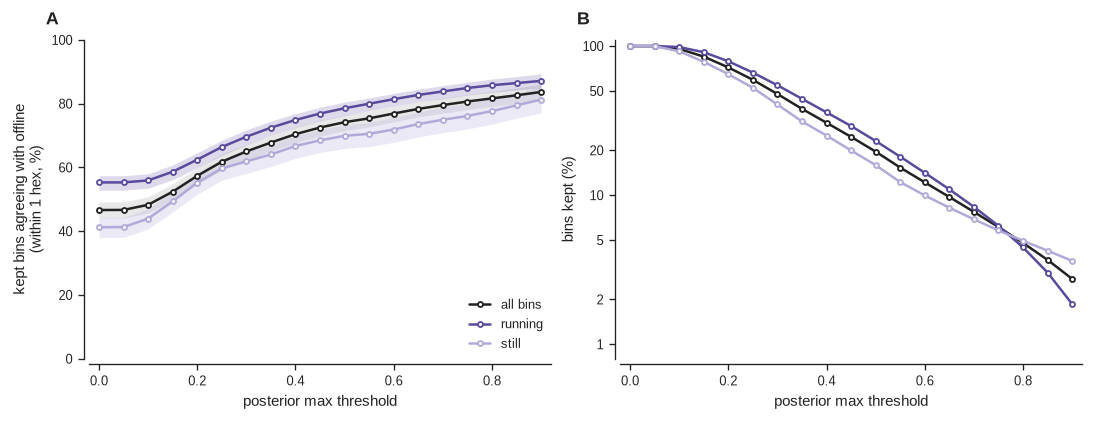

all bins                    running                      still  \
           agree %    lo    hi kept % agree %    lo    hi kept % agree %   
threshold                                                                  
0.0           46.6  44.1  49.1  100.0    55.3  52.9  57.4  100.0    41.2   
0.2           57.3  54.6  59.8   71.9    62.4  59.8  64.6   79.0    55.2   
0.3           65.0  62.3  67.3   47.7    69.6  67.0  71.8   54.6    61.9   
0.4           70.4  67.7  72.7   30.6    74.9  72.5  76.9   35.9    66.7   
0.5           74.2  71.5  76.4   19.6    78.6  76.3  80.5   23.1    69.9   
0.6           76.9  74.3  79.1   12.2    81.4  79.2  83.2   14.1    71.9   
0.7           79.5  77.0  81.8    7.7    83.8  81.6  85.7    8.3    75.0   
0.8           81.6  79.1  83.9    4.8    85.8  83.6  87.7    4.5    77.7   
0.9           83.7  81.0  86.1    2.7    87.1  84.9  89.4    1.9    81.3   

                              
             lo    hi kept %  
threshold                     
0.0        38.0  44.2  100.0  
0.2        51.6  58.3   64.8  
0.3        58.1  65.0   40.6  
0.4        62.8  70.0   25.1  
0.5        65.9  73.3   15.9  
0.6        67.8  75.6   10.0  
0.7        70.9  78.8    6.9  
0.8        73.6  81.6    4.9  
0.9        77.1  85.3    3.6

In [5]:
AG = {lab: thr_curve(blk, lambda t: m & (pm >= t) & agree, lambda t: m & (pm >= t)) for lab, m, _, _ in GROUPS}
KEPT = {lab: 100 * np.array([(m & (pm >= t)).sum() / m.sum() for t in THRESH]) for lab, m, _, _ in GROUPS}

fig, (a0, a1) = plt.subplots(1, 2, figsize=(9, 3.4))
for lab, _, c, ba in GROUPS:
    ci_line(a0, AG[lab].index, AG[lab], c, label=lab, band_alpha=ba, ms=3)
    a1.plot(THRESH, KEPT[lab], color=c, marker='o', ms=3, mfc='white', mew=1.1, label=lab)
thr_axes(a0, f'kept bins agreeing with offline\n(within {AGREE_TOL} hex, %)')
thr_axes(a1, 'bins kept (%)', ylim=None); log_pct_axis(a1)
a0.legend(loc='lower right')
letter([a0, a1])
show(fig, 'trust01_agreement')

tab = pd.concat({lab: AG[lab][['rate', 'lo', 'hi']].rename(columns={'rate': 'agree %'})
                      .assign(**{'kept %': pd.Series(KEPT[lab], index=THRESH)}) for lab, *_ in GROUPS}, axis=1)
display(tab.loc[[0, .2, .3, .4, .5, .6, .7, .8, .9]].round(1))

**Figure 1.** **A**, Agreement with offline (within 1 hex) among the bins that pass each posterior-max
threshold, for all, running and still bins; bands: 95% CI. **B**, Share of each group's bins that pass (log axis).

**Takeaway.**

- **Agreement climbs steadily:** 43% → 62% at ≥ 0.3 → 70% at ≥ 0.5 → 78% at ≥ 0.9 (all bins).
- **Running is always ahead of still:** 53% vs 36% with no threshold, 77% vs 63% at ≥ 0.5, 84% vs 76% at ≥ 0.9. The
  gap narrows only at the very top.
- **Coverage pays for it:** ≥ 0.3 keeps 42% of bins, ≥ 0.5 keeps 18%, ≥ 0.7 keeps 7%. Above about 0.75, still bins
  survive more often than running ones.

## 4 · Goal 1b — non-local content under each threshold

Non-local bins only (decoded position > 20 cm from the rat). With offline as the reference:

- **A — kept:** the share of realtime's non-local bins that pass the threshold;
- **B — precision:** of realtime's kept non-local bins, the share within 1 hex of offline's decode;
- **C — recall:** of offline's non-local bins, the share where realtime passes the threshold *and* is within 1 hex of
  offline.

The table adds how often offline is non-local at all in realtime's kept non-local bins (i.e. "something non-local is
happening", wherever it is).

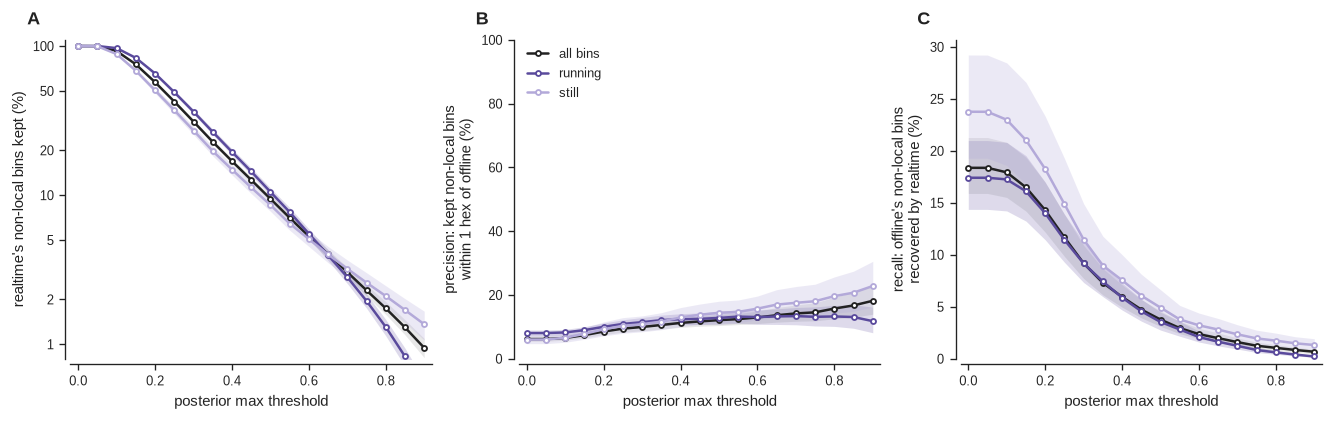

all bins:


,realtime non-local kept %,precision %,offline also non-local %,recall %
threshold,,,,
0.0,100.0,6.1,17.8,18.4
0.2,57.2,8.5,18.6,14.3
0.3,31.1,9.9,19.1,9.2
0.4,16.9,11.2,20.1,5.9
0.5,9.5,12.1,20.8,3.8
0.6,5.3,12.9,22.0,2.4
0.7,3.0,14.2,23.2,1.6
0.8,1.7,15.7,24.3,1.0
0.9,0.9,18.2,25.4,0.7


In [6]:
rt_nl, of_nl = pairs.rt_nl.to_numpy(), pairs.of_nl.to_numpy()
NLC = {}
for lab, m, _, _ in GROUPS:
    NLC[lab, 'kept']      = thr_curve(blk, lambda t: m & rt_nl & (pm >= t), lambda t: m & rt_nl)
    NLC[lab, 'precision'] = thr_curve(blk, lambda t: m & rt_nl & (pm >= t) & agree, lambda t: m & rt_nl & (pm >= t))
    NLC[lab, 'recall']    = thr_curve(blk, lambda t: m & of_nl & (pm >= t) & agree, lambda t: m & of_nl)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, metric, yl in [(axes[0], 'kept', "realtime's non-local bins kept (%)"),
                       (axes[1], 'precision', 'precision: kept non-local bins\nwithin 1 hex of offline (%)'),
                       (axes[2], 'recall', "recall: offline's non-local bins\nrecovered by realtime (%)")]:
    for lab, _, c, ba in GROUPS:
        ci_line(ax, NLC[lab, metric].index, NLC[lab, metric], c, label=lab, band_alpha=ba, ms=3)
    thr_axes(ax, yl, ylim=(0, 100) if metric == 'precision' else (0, None))
    if metric == 'kept':
        log_pct_axis(ax)
axes[1].legend(loc='upper left')
letter(axes)
show(fig, 'trust02_nonlocal_bins')

rows = []
for t in [0, .2, .3, .4, .5, .6, .7, .8, .9]:
    k_ = rt_nl & (pm >= t)
    rows.append({'threshold': t, 'realtime non-local kept %': 100 * k_.sum() / rt_nl.sum(),
                 'precision %': 100 * agree[k_].mean(), 'offline also non-local %': 100 * of_nl[k_].mean(),
                 'recall %': 100 * (of_nl & (pm >= t) & agree).sum() / of_nl.sum()})
print('all bins:')
display(pd.DataFrame(rows).set_index('threshold').round(1))

**Figure 2.** Non-local bins (decoded > 20 cm from the rat). **A**, Share of realtime's non-local bins that
pass the threshold (log axis). **B**, Precision: of those, the share within 1 hex of offline. **C**, Recall: of
offline's non-local bins, the share where realtime passes the threshold and is within 1 hex of offline. Bands: 95% CI.

**Takeaway.**

- **Realtime calls far more bins non-local than offline:** 55% against 12%.
- **Precision stays low at every threshold:** 6% with no threshold, 10% at ≥ 0.5, 14% at ≥ 0.9. In about 80% of
  realtime's kept non-local bins, offline isn't non-local at all, so these are realtime errors, not missed replay.
- **Recall falls fast:** realtime recovers 18% of offline's non-local bins with no threshold (22% at rest), 7.5% at
  ≥ 0.3, 3% at ≥ 0.5 and under 1% at ≥ 0.9.
- **Bottom line for goal 1:** posterior max can buy local accuracy, but no threshold makes realtime's bin-by-bin
  non-local content trustworthy in this run.

## 5 · Goal 2 — non-local events under each threshold

**Building the events.** The two functions below are copied verbatim from
`~/Desktop/continuous_fragmented_replay_fetching.ipynb` (only the defaults are shared). Offline events come from the
offline file at its native 2 ms resolution (`min_dwell_bins` = 10 = 20 ms); realtime events from the realtime bins
(6 ms; `min_dwell_bins` = 4 ≈ 20 ms), using realtime's decoded hex centre as its position and the same tracked rat
position as offline.

**Scoring at a threshold t.** A realtime event is *kept* if its mean posterior max ≥ t.
- **precision:** of the kept realtime events, the share that *agree* (overlap an offline event, and in the overlapping
  bins realtime is within 1 hex of offline at least half the time);
- **recall:** of offline's events, the share recovered: the realtime bins inside the offline event that belong to kept
  realtime events exist, and at least half of them are within 1 hex of offline.

Events are grouped by the rat's mean speed during the event.

In [7]:
# ---- copied from ~/Desktop/continuous_fragmented_replay_fetching.ipynb ----
def find_nonlocal_intervals(
    df,
    dist_thresh=20.0,      # cm
    min_duration=0.080,    # s
    decoded_cols=("decode_position_x", "decode_position_y"),
    real_cols=("position_x", "position_y"),
    max_gap=None,          # s; if None, inferred as 2x median sample interval
):
    times = df.index.to_numpy(dtype=float)
    px = df[decoded_cols[0]].to_numpy()
    py = df[decoded_cols[1]].to_numpy()
    rx = df[real_cols[0]].to_numpy()
    ry = df[real_cols[1]].to_numpy()
    dist = np.hypot(px - rx, py - ry)
    step_dist = np.hypot(np.diff(px), np.diff(py))
    is_nonlocal = dist > dist_thresh          # NaN -> False
    if max_gap is None:
        dt = np.diff(times)
        max_gap = 2 * np.median(dt[dt > 0]) if len(dt) else np.inf
    gap_break = np.concatenate(([False], np.diff(times) > max_gap))
    run_id = np.cumsum(gap_break)
    rows = []
    n = len(is_nonlocal)
    i = 0
    while i < n:
        if not is_nonlocal[i]:
            i += 1
            continue
        j = i
        while j + 1 < n and is_nonlocal[j + 1] and run_id[j + 1] == run_id[i]:
            j += 1
        duration = times[j] - times[i]
        if duration > min_duration:
            rows.append({"start_time": times[i], "end_time": times[j], "interval": [times[i], times[j]],
                         "duration": duration, "n_samples": j - i + 1,
                         "max_distance": np.nanmax(dist[i : j + 1]), "mean_distance": np.nanmean(dist[i : j + 1]),
                         "travel_distance": float(np.nansum(step_dist[i:j]))})
        i = j + 1
    return pd.DataFrame(rows, columns=["start_time", "end_time", "interval", "duration", "n_samples",
                                       "max_distance", "mean_distance", "travel_distance"])

def split_nonlocal_intervals(
    df, intervals_df, jump_thresh=20.0, min_dwell_bins=10,
    decoded_cols=("decode_position_x", "decode_position_y"), real_cols=("position_x", "position_y"),
):
    times = df.index.to_numpy(dtype=float)
    px = df[decoded_cols[0]].to_numpy()
    py = df[decoded_cols[1]].to_numpy()
    rx = df[real_cols[0]].to_numpy()
    ry = df[real_cols[1]].to_numpy()
    dist = np.hypot(px - rx, py - ry)
    step_dist = np.hypot(np.diff(px), np.diff(py))
    rows = []
    for parent_id, ev in intervals_df.iterrows():
        i = int(np.searchsorted(times, ev["start_time"]))
        j = int(np.searchsorted(times, ev["end_time"]))
        assert times[i] == ev["start_time"] and times[j] == ev["end_time"]
        n_bins = j - i + 1
        breaks = np.flatnonzero(step_dist[i:j] > jump_thresh) + 1
        bounds = np.concatenate(([0], breaks, [n_bins]))
        segments = []
        for a, b in zip(bounds[:-1], bounds[1:]):
            kind = "dwell" if (b - a) >= min_dwell_bins else "unstable"
            if segments and kind == "unstable" and segments[-1][2] == "unstable":
                segments[-1] = (segments[-1][0], b, "unstable")
            else:
                segments.append((a, b, kind))
        for seg_idx, (a, b, kind) in enumerate(segments):
            s, e = i + a, i + b - 1
            rows.append({"start_time": times[s], "end_time": times[e], "interval": [times[s], times[e]],
                         "duration": times[e] - times[s], "n_samples": b - a,
                         "max_distance": np.nanmax(dist[s : e + 1]), "mean_distance": np.nanmean(dist[s : e + 1]),
                         "travel_distance": float(np.nansum(step_dist[s:e])), "segment_type": kind,
                         "parent_event_id": parent_id, "segment_index": seg_idx, "n_segments": len(segments),
                         "jump_distance": step_dist[s - 1] if a > 0 else np.nan})
    return pd.DataFrame(rows, columns=["start_time", "end_time", "interval", "duration", "n_samples",
                                       "max_distance", "mean_distance", "travel_distance", "segment_type",
                                       "parent_event_id", "segment_index", "n_segments", "jump_distance"])
# ---- end of copied code ----

def build_events(df, dwell_bins):
    parents = find_nonlocal_intervals(df, dist_thresh=NONLOCAL_CM, min_duration=MIN_EVENT_S)
    segs = split_nonlocal_intervals(df, parents, jump_thresh=JUMP_CM, min_dwell_bins=dwell_bins)
    return {'dwell': segs[segs.segment_type == 'dwell'].reset_index(drop=True), 'parent': parents}

of_df = of[['decode_position_x', 'decode_position_y', 'position_x', 'position_y']]
rt_df = pd.DataFrame({'decode_position_x': pairs.rt_x.to_numpy(), 'decode_position_y': pairs.rt_y.to_numpy(),
                      'position_x': pairs.rat_x.to_numpy(), 'position_y': pairs.rat_y.to_numpy()},
                     index=pairs.t.to_numpy())
EV = {'offline': build_events(of_df, int(round(MIN_DWELL_S / np.median(np.diff(t_of))))),
      'realtime': build_events(rt_df, int(np.ceil(MIN_DWELL_S / BIN_S)))}
display(pd.DataFrame({f'{src} {kind}': {'events': len(e), 'per minute': len(e) / (len(pairs) * BIN_S / 60),
                                       'median ms': 1e3 * e.duration.median()}
                      for src, d in EV.items() for kind, e in d.items()}).round(1))

,offline dwell,offline parent,realtime dwell,realtime parent
events,1906.0,1416.0,17992.0,6954.0
per minute,41.7,30.9,393.2,152.0
median ms,78.0,106.0,36.0,60.0


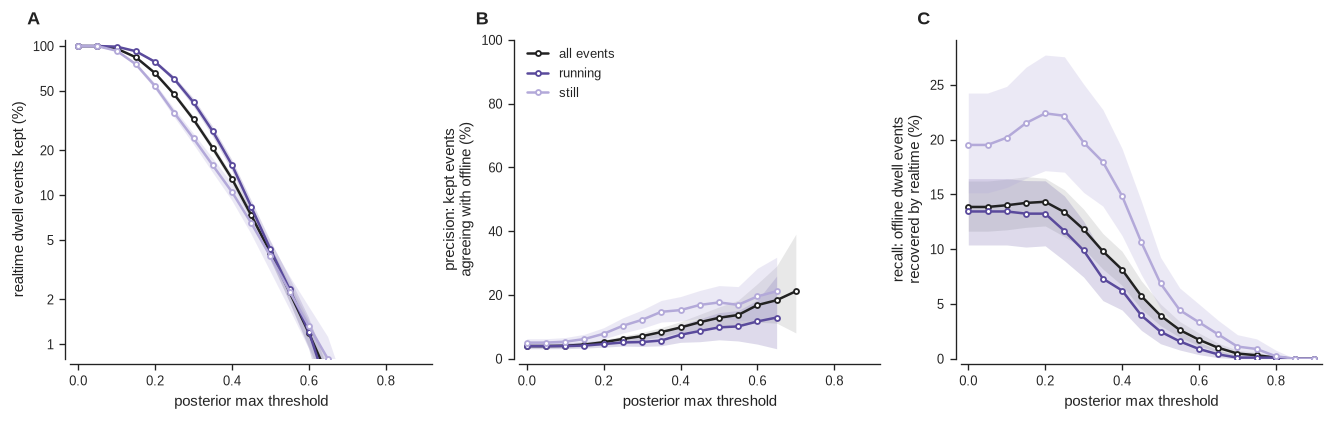

all events (dwell = the figure; parent intervals alongside):


realtime events kept %  precision %  recall %
events threshold                                               
dwell  0.0                         100.0          4.0      13.9
       0.2                          65.8          5.2      14.3
       0.3                          32.2          7.1      11.8
       0.4                          12.9          9.8       8.1
       0.5                           4.1         12.8       3.9
       0.6                           1.2         16.8       1.7
       0.7                           0.3         21.2       0.5
parent 0.0                         100.0          4.0      14.5
       0.2                          75.5          4.7      13.8
       0.3                          32.7          6.6       9.2
       0.4                           9.9          8.4       3.3
       0.5                           2.7         11.1       1.4
       0.6                           0.7         14.6       0.5
       0.7                           0.0          0.0       0.0

In [8]:
tb  = pairs.t.to_numpy()
spd = np.r_[0, np.cumsum(pairs.speed.to_numpy())]
cpm = np.r_[0, np.cumsum(pm)]
spd_of = np.r_[0, np.cumsum(of.speed.to_numpy())]

def bin_membership(ev):
    # for every realtime bin, the id of the event (start_time..end_time) containing it, else -1
    st, en = ev.start_time.to_numpy(), ev.end_time.to_numpy()
    k = np.searchsorted(st, tb, side='right') - 1
    return np.where((k >= 0) & (tb <= en[k.clip(0)]), k, -1)

def event_scores(kind):
    rte, ofe = EV['realtime'][kind], EV['offline'][kind]
    rt_id, of_id = bin_membership(rte), bin_membership(ofe)
    # realtime events: index range in bins, mean posterior max, mean speed, agreement with offline
    s = np.searchsorted(tb, rte.start_time.to_numpy()); e = np.searchsorted(tb, rte.end_time.to_numpy()) + 1
    r = pd.DataFrame({'mean_pm': (cpm[e] - cpm[s]) / (e - s), 'speed': (spd[e] - spd[s]) / (e - s),
                      'block': blk[s]})
    ov  = np.bincount(rt_id[(rt_id >= 0) & (of_id >= 0)], minlength=len(rte))
    ovs = np.bincount(rt_id[(rt_id >= 0) & (of_id >= 0) & agree], minlength=len(rte))
    r['agree'] = (ov > 0) & (ovs >= 0.5 * ov)
    # offline events: mean speed (offline samples), 30 s chunk of the start
    so = np.searchsorted(t_of, ofe.start_time.to_numpy()); eo = np.searchsorted(t_of, ofe.end_time.to_numpy()) + 1
    o = pd.DataFrame({'speed': (spd_of[eo] - spd_of[so]) / (eo - so),
                      'block': ((ofe.start_time.to_numpy() - tb[0]) // BLOCK_S).astype(int).clip(0, NB - 1)})
    def recovered(t):
        kept_bin = (rt_id >= 0) & (r.mean_pm.to_numpy()[rt_id.clip(0)] >= t) & (of_id >= 0)
        n_k  = np.bincount(of_id[kept_bin], minlength=len(ofe))
        n_ks = np.bincount(of_id[kept_bin & agree], minlength=len(ofe))
        return (n_k > 0) & (n_ks >= 0.5 * n_k)
    return r, o, recovered

def event_groups(speed):
    return [('all events', np.ones(len(speed), bool), INK, .1), ('running', speed > RUN_SPEED, RUN_C, .2),
            ('still', speed < STILL_SPEED, STILL_C, .25)]

ES = {}
for kind in ['dwell', 'parent']:
    r, o, recovered = event_scores(kind)
    rb, ob = r.block.to_numpy(), o.block.to_numpy()
    rpm, rag = r.mean_pm.to_numpy(), r.agree.to_numpy()
    for (lab, m, _, _), (_, mo, _, _) in zip(event_groups(r.speed.to_numpy()), event_groups(o.speed.to_numpy())):
        ES[kind, lab, 'kept']      = thr_curve(rb, lambda t: m & (rpm >= t), lambda t: m, min_n=30)
        ES[kind, lab, 'precision'] = thr_curve(rb, lambda t: m & (rpm >= t) & rag, lambda t: m & (rpm >= t), min_n=30)
        ES[kind, lab, 'recall']    = thr_curve(ob, lambda t: mo & recovered(t), lambda t: mo, min_n=30)
    ES[kind, 'tables'] = (r, o, recovered)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, metric, yl in [(axes[0], 'kept', 'realtime dwell events kept (%)'),
                       (axes[1], 'precision', 'precision: kept events\nagreeing with offline (%)'),
                       (axes[2], 'recall', "recall: offline dwell events\nrecovered by realtime (%)")]:
    for lab, _, c, ba in event_groups(np.zeros(1)):
        cv = ES['dwell', lab, metric]
        ci_line(ax, cv.index, cv, c, label=lab, band_alpha=ba, ms=3)
    thr_axes(ax, yl, ylim=(0, 100) if metric == 'precision' else (0, None))
    if metric == 'kept':
        log_pct_axis(ax)
axes[1].legend(loc='upper left')
letter(axes)
show(fig, 'trust03_nonlocal_events')

rows = []
for kind in ['dwell', 'parent']:
    r, o, recovered = ES[kind, 'tables']
    for t in [0, .2, .3, .4, .5, .6, .7]:
        kept = r.mean_pm >= t
        rows.append({'events': kind, 'threshold': t, 'realtime events kept %': 100 * kept.mean(),
                     'precision %': 100 * r.agree[kept].mean(), 'recall %': 100 * recovered(t).mean()})
print('all events (dwell = the figure; parent intervals alongside):')
display(pd.DataFrame(rows).set_index(['events', 'threshold']).round(1))

**Figure 3.** Non-local **dwell** events. **A**, Share of realtime's events whose mean posterior max passes the
threshold (log axis). **B**, Precision: of those, the share that agree with offline (overlap an offline event, and
within 1 hex of offline in at least half the overlapping bins). **C**, Recall: of offline's events, the share recovered
by kept, agreeing realtime bins. Grouped by the rat's mean speed during the event. Bands: 95% CI (events resampled by
30 s chunk); curves end where fewer than 30 events remain.

**Takeaway.**

- **Realtime has ~10× more non-local events than offline, and shorter ones:** 439 dwell events a minute (median
  30 ms) against 42 (median 78 ms).
- **Their confidence is low.** Only 4% of realtime's dwell events have a mean posterior max ≥ 0.5, and almost none get
  past 0.7.
- **Precision:** 4% with no threshold, 11% at ≥ 0.5, and about 19% at ≥ 0.7, by which point only 0.4% of events
  remain. At rest it reaches ~23%, with a wide CI.
- **Recall:** 13% of offline's dwell events are recovered with no threshold (still events: 20–22% up to ≥ 0.2), 4% at
  ≥ 0.5 and under 1% at ≥ 0.7.
- **Parent intervals behave the same or worse** (precision 3% → 9% at ≥ 0.5; recall 12% → 1%).
- **Bottom line for goal 2:** realtime's non-local events rarely match offline's, and the posterior-max threshold
  cannot fix that in this run.

## 6 · Confident ground truth only

Offline is the reference, but it is sometimes unsure itself; scoring realtime against an unsure offline decode can
make realtime look worse than it is. Here bins are split into thirds by **offline's own uncertainty** (`spatial_cov`,
the size of its highest-density region — smaller = more confident; this reading of the column is mine) and the
agreement curves from §3 are redrawn per third. If the most-confident third agrees much better, part of the
disagreement is the reference's fault.

offline spatial_cov cut points (thirds): [44. 73.]


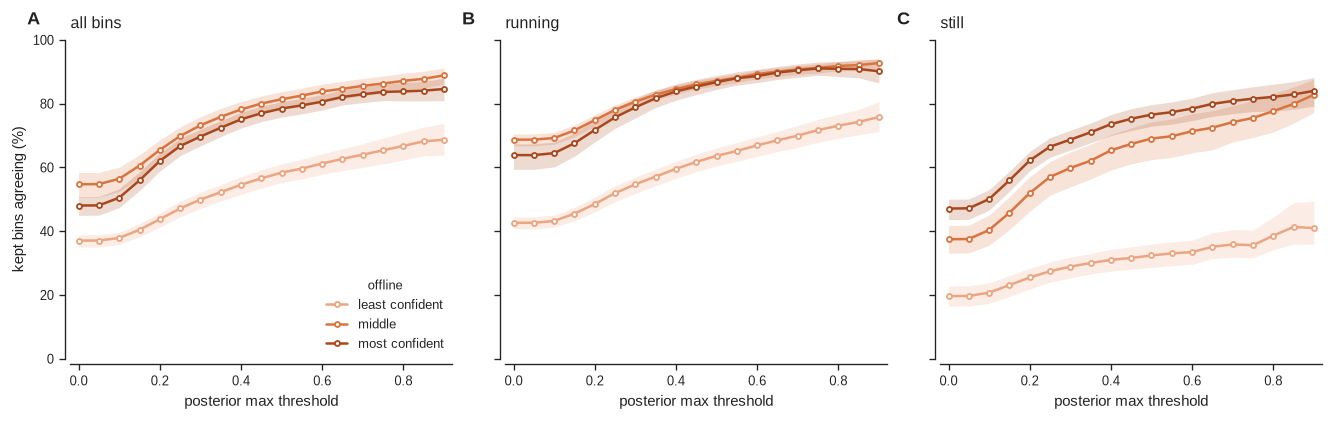

share of group %  agree % (no threshold)  \
offline         group                                                
least confident all bins              32.7                    37.0   
                running               48.9                    42.6   
                still                 13.3                    19.7   
middle          all bins              32.7                    54.7   
                running               37.5                    68.7   
                still                 23.1                    37.5   
most confident  all bins              34.6                    48.0   
                running               13.6                    63.9   
                still                 63.7                    47.1   

                          agree % (>= 0.5)  non-local precision % (>= 0.5)  \
offline         group                                                        
least confident all bins              58.4                            13.6   
                running               63.6                            13.4   
                still                 32.4                            16.1   
middle          all bins              81.4                            12.8   
                running               87.1                            14.4   
                still                 69.1                            18.9   
most confident  all bins              78.5                             9.6   
                running               86.7                             6.6   
                still                 76.6                            11.8   

                          % at a corner hex  
offline         group                        
least confident all bins               28.9  
                running                15.7  
                still                  67.8  
middle          all bins               42.1  
                running                13.6  
                still                  81.7  
most confident  all bins               80.4  
                running                21.2  
                still                  96.7

In [9]:
tert = pd.qcut(pairs.of_spread, 3, labels=['most confident', 'middle', 'least confident']).to_numpy()
print('offline spatial_cov cut points (thirds):', np.round(pairs.of_spread.quantile([1/3, 2/3]).to_numpy(), 1))
TER = [(lab, tert == lab, c) for lab, c in zip(['least confident', 'middle', 'most confident'], OF_RAMP)]

fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
for ax, (glab, gm, _, _) in zip(axes, GROUPS):
    for lab, tm, c in TER:
        m = gm & tm
        cv = thr_curve(blk, lambda t: m & (pm >= t) & agree, lambda t: m & (pm >= t))
        ci_line(ax, cv.index, cv, c, label=lab, ms=3)
    thr_axes(ax, f'kept bins agreeing (%)' if glab == 'all bins' else '')
    ax.set_title(glab)
axes[0].legend(loc='lower right', title='offline', title_fontsize=8)
letter(axes)
show(fig, 'trust04_confident_ground_truth')

rows = []
for lab, tm, _ in TER:
    for glab, gm, _, _ in GROUPS:
        m = gm & tm
        rows.append({'offline': lab, 'group': glab, 'share of group %': 100 * m.sum() / gm.sum(),
                     'agree % (no threshold)': 100 * agree[m].mean(), 'agree % (>= 0.5)': 100 * agree[m & (pm >= .5)].mean(),
                     'non-local precision % (>= 0.5)': 100 * agree[m & rt_nl & (pm >= .5)].mean(),
                     '% at a corner hex': 100 * pairs.of_act[m].isin([1, 2, 3]).mean()})
display(pd.DataFrame(rows).set_index(['offline', 'group']).round(1))

**Figure 4.** Agreement above each threshold, with bins split into thirds by **offline's** uncertainty
(`spatial_cov`): darkest = offline most confident. **A**, All bins. **B**, Running. **C**, Still. Bands: 95% CI.

**Takeaway.**

- **When offline itself is unsure, agreement collapses:** 35% with no threshold (still bins: 17%) and still only 55%
  at ≥ 0.5 (still: 26%). The other two thirds start at 43–52% and reach 73–78% at ≥ 0.5.
- **At rest, much of the disagreement sits where the reference is unsure.** In the least-confident third, still-bin
  agreement barely moves with the threshold (17% → 29% at ≥ 0.9).
- **"Most confident" isn't the best-agreeing third overall,** because it is mostly the corner hexes (80% of its bins;
  97% of its still bins), where realtime's blind spot is.
- **Non-local precision is low in every third** (8–15% at ≥ 0.5), so the non-local problem isn't caused by a noisy
  reference.

## 7 · Expected agreement for a threshold — measured on half, checked on the other half

The threshold you would set in the experiment means **"act only on bins with posterior max ≥ t"**, so the number that
matters is the agreement over **all bins at or above t**, not inside a narrow band. §3 shows that on the whole
session. This section asks whether those numbers **carry over to data they weren't measured on**:

- **expected**: agreement among bins ≥ t, measured on the training chunks (alternating 2-minute chunks);
- **held-out**: the same quantity on the other chunks, with a 95% CI.

If the held-out points sit on the expected curve (panel A) and on the diagonal (panel B), the threshold → agreement
table can be trusted as a lookup. The running/still split uses offline's speed, as everywhere in this notebook; live,
the realtime system would have to use its own speed estimate.

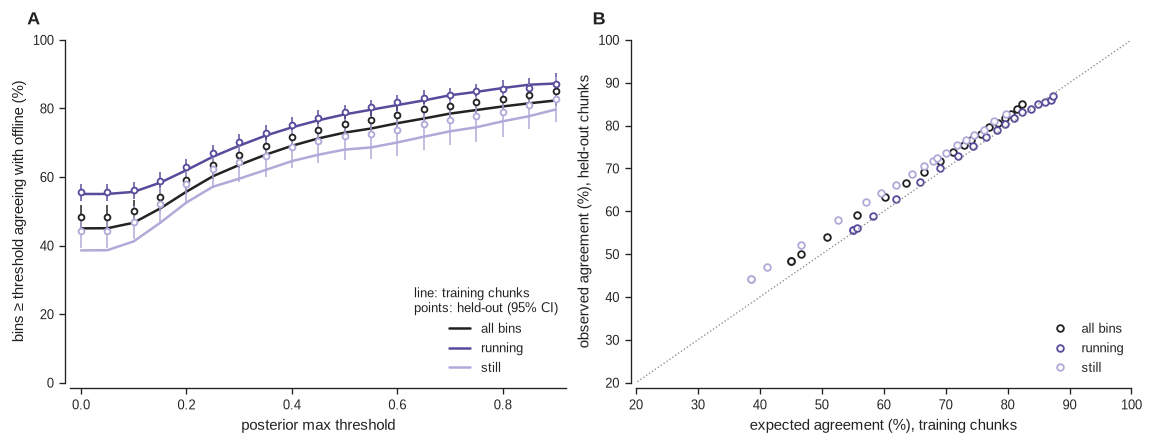

lookup: act only on bins with posterior max >= threshold


all bins                                           running  \
                 expected % held-out % held-out 95% CI bins kept % expected %   
posterior max >=                                                                
0.1                    46.7       50.0       46.1–53.4        96.0       55.7   
0.2                    55.7       59.1       55.0–62.3        72.8       62.0   
0.3                    63.5       66.6       62.6–69.8        48.4       69.1   
0.4                    69.1       71.8       67.7–74.9        31.2       74.5   
0.5                    72.9       75.5       71.5–78.3        20.0       78.3   
0.6                    75.7       78.1       74.0–81.2        12.4       81.0   
0.7                    78.5       80.6       76.4–83.6         7.9       83.8   
0.8                    80.6       82.8       78.6–85.8         4.8       86.0   
0.9                    82.3       85.1       80.7–88.4         2.8       87.3   

                                                             still             \
                 held-out % held-out 95% CI bins kept % expected % held-out %   
posterior max >=                                                                
0.1                    56.2       53.5–58.7        98.5       41.2       46.9   
0.2                    62.9       60.3–65.3        78.8       52.6       58.0   
0.3                    70.1       67.5–72.4        54.1       59.5       64.3   
0.4                    75.3       72.8–77.5        35.6       64.6       68.8   
0.5                    78.9       76.4–81.0        22.9       68.0       71.8   
0.6                    81.8       79.3–83.9        14.0       70.1       73.7   
0.7                    83.8       81.1–86.0         8.3       73.3       76.5   
0.8                    85.6       82.4–88.3         4.4       76.3       79.1   
0.9                    87.0       83.4–90.2         1.8       79.7       82.8   

                                              
                 held-out 95% CI bins kept %  
posterior max >=                              
0.1                    41.9–51.5        92.7  
0.2                    52.5–62.7        66.6  
0.3                    58.5–69.0        42.4  
0.4                    62.5–73.7        26.5  
0.5                    65.1–76.9        16.8  
0.6                    66.2–79.3        10.5  
0.7                    69.4–82.4         7.3  
0.8                    71.7–85.2         5.2  
0.9                    76.0–89.1         3.9

In [10]:
train = pairs.train.to_numpy()
test  = ~train

EXP = {}
for lab, m, _, _ in GROUPS:
    tr, te = m & train, m & test
    expected = pd.Series([100 * agree[tr & (pm >= t)].mean() if (tr & (pm >= t)).sum() >= MIN_N else np.nan
                          for t in THRESH], index=THRESH)
    held = thr_curve(blk, lambda t: te & (pm >= t) & agree, lambda t: te & (pm >= t))
    kept = pd.Series([100 * (te & (pm >= t)).sum() / te.sum() for t in THRESH], index=THRESH)
    EXP[lab] = held.assign(expected=expected, kept=kept)

fig, (a0, a1) = plt.subplots(1, 2, figsize=(9.5, 3.6))
for lab, _, c, _ in GROUPS:
    e = EXP[lab]
    a0.plot(THRESH, e.reindex(THRESH).expected, color=c, label=f'{lab}')
    a0.errorbar(e.index, e.rate, yerr=[e.rate - e.lo, e.hi - e.rate], fmt='o', ms=3.5, color=c, mfc='white',
                mew=1.1, elinewidth=0.9, capsize=0)
    a1.plot(e.expected, e.rate, 'o', ms=4, color=c, mfc='white', mew=1.1, label=lab)
thr_axes(a0, f'bins ≥ threshold agreeing with offline (%)')
a0.legend(loc='lower right', title='line: training chunks\npoints: held-out (95% CI)', title_fontsize=7.5)
a1.plot([0, 100], [0, 100], color=MUTED, lw=0.8, ls=':')
a1.set_xlim(20, 100); a1.set_ylim(20, 100)
a1.set_xlabel('expected agreement (%), training chunks'); a1.set_ylabel('observed agreement (%), held-out chunks')
a1.legend(loc='lower right')
letter([a0, a1])
show(fig, 'trust05_expected_agreement')

LOOK = [0.1, .2, .3, .4, .5, .6, .7, .8, .9]
print('lookup: act only on bins with posterior max >= threshold')
display(pd.concat({lab: EXP[lab].reindex(LOOK).assign(
            **{'held-out 95% CI': lambda d: [f'{a:.1f}–{b:.1f}' for a, b in zip(d.lo, d.hi)]})
            [['expected', 'rate', 'held-out 95% CI', 'kept']]
            .rename(columns={'expected': 'expected %', 'rate': 'held-out %', 'kept': 'bins kept %'})
        for lab, *_ in GROUPS}, axis=1).rename_axis('posterior max >=').round(1))

**Figure 5.** Agreement with offline (within 1 hex) among **all bins at or above** each posterior-max
threshold. **A**, Lines: measured on the training chunks; points: the held-out chunks, with 95% CI. **B**, Held-out vs
training value, one point per threshold and group; dotted line = perfect transfer.

**Takeaway.**

- **The threshold → agreement numbers carry over to unseen data.** Running bins match within about 1 point at every
  threshold (≥ 0.5: 76.9% expected, 77.2% held out). Still bins come out 3–5 points *better* than expected, inside the
  CI. Their CIs are wide (about ±7 points) because rest comes in long stretches.
- **Lookup, held-out values:**

  | posterior max ≥ | running agree | running bins kept | still agree | still bins kept |
  |---|---|---|---|---|
  | 0.3 | 69% | 49% | 58% | 35% |
  | 0.5 | 77% | 21% | 64% | 15% |
  | 0.7 | 81% | 8% | 69% | 7% |
  | 0.9 | 84% | 2% | 77% | 4% |

- **Diminishing returns while running:** going from 0.5 to 0.9 adds only about 6 points of agreement, but the kept
  bins drop from 21% to 2%.
- **One session:** the chunks all come from this session, so a new session is the real test of transfer.

## 8 · Trust by decoded place

When realtime says "the content is at hex X", how often is offline within 1 hex of X? This is precision by *decoded*
location (not by where the rat is), drawn on the maze at three thresholds. Grey hexes: fewer than `MIN_N` bins.

**Map layout.** Black outline = a barrier in every block, i.e. never available this session (hexes 5, 17, 23, 30, 32, 37, 39, the intersection of the five block configurations). Pink outline = a barrier in some blocks only (14, 16, 18, 19, 24, 31, 45; the legend says which blocks). The maze is rotated so that port 2 (hex 2) is bottom-left and port 3 (hex 3) bottom-right. It is a rotation, not a mirror image, so neighbours and the order of hexes around the maze are unchanged.

barrier in every block (unavailable all session): [5, 17, 23, 30, 32, 37, 39]
barrier in some blocks only: 14 (B1), 16 (B1–B3), 18 (B4–B5), 19 (B2–B5), 24 (B5), 31 (B3–B4), 45 (B1–B2)
rotated by 117°;  port hexes around the maze centre: hex 1 86°, hex 2 210°, hex 3 328°  (90° = top, 210° = bottom-left, 330° = bottom-right)


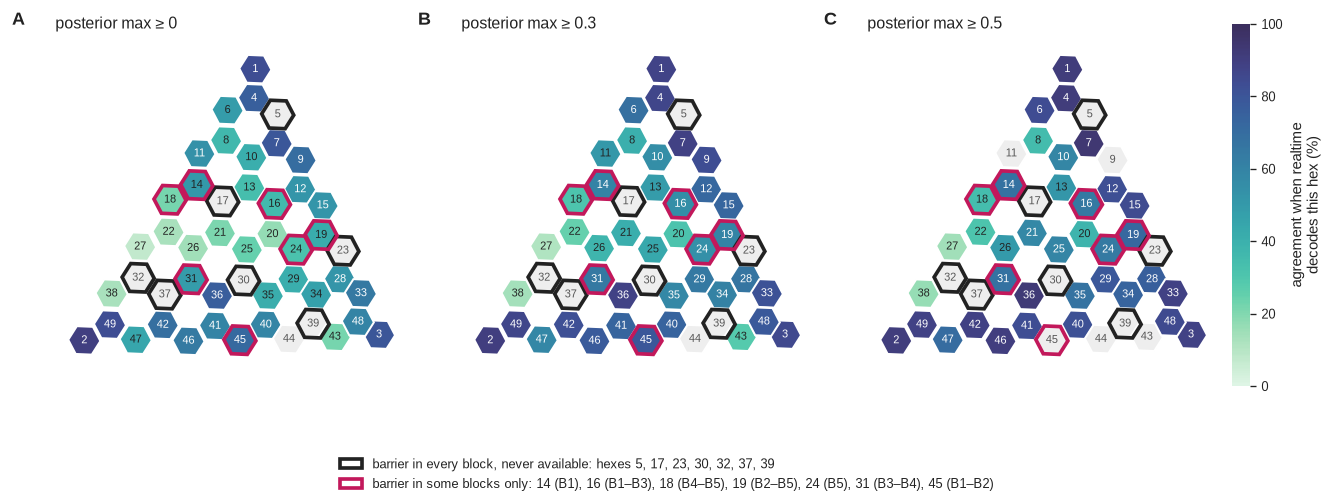

the 12 most-decoded hexes:


,agree % (≥ 0),n (≥ 0),agree % (≥ 0.3),n (≥ 0.3),agree % (≥ 0.5),n (≥ 0.5),share of decodes %,barrier in
rt_dec,,,,,,,,
49,83.0,62674,87.0,35563,88.6,13264,13.7,
22,13.1,54864,24.9,17829,30.7,6304,12.0,
21,20.9,37810,40.7,13427,58.1,4407,8.3,
2,89.6,32472,90.4,29361,90.8,18544,7.1,
25,24.8,27426,43.8,10663,59.3,3745,6.0,
4,75.6,21946,87.0,11148,91.4,3317,4.8,
26,14.7,18855,37.7,3509,49.7,1143,4.1,
16,35.4,15782,55.3,6646,64.6,2642,3.4,B1–B3
1,83.6,13264,87.8,10115,91.3,5809,2.9,


In [11]:
# barriers per block (maze configurations); a hex that is a barrier in every block is never available
BARRIER_BLOCKS = {
    'b1': {39, 23, 45, 30, 16, 5, 17, 37, 14, 32},
    'b2': {39, 23, 19, 45, 30, 16, 5, 17, 37, 32},
    'b3': {39, 23, 19, 30, 16, 31, 5, 17, 37, 32},
    'b4': {39, 23, 19, 30, 31, 5, 17, 37, 32, 18},
    'b5': {39, 23, 19, 24, 30, 5, 17, 37, 32, 18},
}
ALWAYS_BARRIER = sorted(set.intersection(*BARRIER_BLOCKS.values()))
SOME_BARRIER   = sorted(set.union(*BARRIER_BLOCKS.values()) - set(ALWAYS_BARRIER))   # barrier in some blocks only
SOME_C = '#c2185b'                                       # outline colour for the part-time barriers

def barrier_blocks(h):
    # e.g. 'B2–B5' for a hex that is a barrier in blocks 2 to 5
    b = [int(k[1:]) for k, v in BARRIER_BLOCKS.items() if h in v]
    return '' if not b else ('all blocks' if len(b) == len(BARRIER_BLOCKS) else
                             f'B{b[0]}' if len(b) == 1 else f'B{b[0]}–B{b[-1]}' if b == list(range(b[0], b[-1] + 1))
                             else ', '.join(f'B{x}' for x in b))
print('barrier in every block (unavailable all session):', ALWAYS_BARRIER)
print('barrier in some blocks only:', ', '.join(f'{h} ({barrier_blocks(h)})' for h in SOME_BARRIER))

# layout: hex centres in cm, shown as the camera sees them (y up), then ROTATED (never mirrored) so that
# port 2 (hex 2) is bottom-left and port 3 (hex 3) bottom-right; neighbours and hex order are unchanged
XY0 = CENT_CM[1:].copy()
if np.corrcoef(cen_px.y, XY0[:, 1])[0, 1] > 0:           # cm y follows image rows (downward) -> flip to y up
    XY0[:, 1] *= -1
ctr = XY0.mean(axis=0)
angle_of = lambda P, h: np.degrees(np.arctan2(P[h - 1, 1] - ctr[1], P[h - 1, 0] - ctr[0])) % 360
ROT = np.radians(210 - angle_of(XY0, 2))                 # hex 2 -> 210° around the maze centre (bottom-left)
Rm  = np.array([[np.cos(ROT), -np.sin(ROT)], [np.sin(ROT), np.cos(ROT)]])
XY  = (XY0 - ctr) @ Rm.T + ctr
ports = {h: angle_of(XY, h) for h in (1, 2, 3)}
assert abs(ports[3] - 330) < 25 and abs(ports[1] - 90) < 25, f'ports would need a mirror image: {ports}'
print(f'rotated by {np.degrees(ROT) % 360:.0f}°;  port hexes around the maze centre: '
      + ', '.join(f'hex {h} {a:.0f}°' for h, a in ports.items()) + '  (90° = top, 210° = bottom-left, 330° = bottom-right)')

dd  = np.hypot(*(XY[:, None, :] - XY[None, :, :]).T); np.fill_diagonal(dd, np.inf)
NNc = float(np.median(dd.min(axis=1)))
nbr = np.argmin(dd, axis=1)
nb_ang = np.arctan2(XY[nbr, 1] - XY[:, 1], XY[nbr, 0] - XY[:, 0])
ORIENT = np.angle(np.mean(np.exp(6j * nb_ang))) / 6       # tile orientation that follows the rotated lattice
RH = NNc / np.sqrt(3) * 0.96

def draw_hex_map(ax, values, n, title, vmin=0, vmax=100):
    norm = mpl.colors.Normalize(vmin, vmax)
    for h, (x_, y_) in zip(HEX_IDS, XY):
        v, shown = values.get(h, np.nan), n.get(h, 0) >= MIN_N
        face = CM_SEQ(norm(v)) if shown and np.isfinite(v) else SHADE
        ax.add_patch(RegularPolygon((x_, y_), 6, radius=RH, orientation=ORIENT, facecolor=face,
                                    edgecolor='white', linewidth=1.2, zorder=1))
        ax.text(x_, y_, str(h), ha='center', va='center', fontsize=6.5, zorder=4,
                color=text_on(face) if face is not SHADE else INK2)
    for hs, ec in [(ALWAYS_BARRIER, INK), (SOME_BARRIER, SOME_C)]:   # drawn last so no neighbour's edge covers them
        for h in hs:
            ax.add_patch(RegularPolygon(tuple(XY[h - 1]), 6, radius=RH, orientation=ORIENT, facecolor='none',
                                        edgecolor=ec, linewidth=2.2, zorder=3))
    ax.set_xlim(XY[:, 0].min() - NNc, XY[:, 0].max() + NNc)
    ax.set_ylim(XY[:, 1].min() - NNc, XY[:, 1].max() + NNc)
    ax.set_aspect('equal'); ax.axis('off'); ax.set_title(title)
    return mpl.cm.ScalarMappable(norm=norm, cmap=CM_SEQ)

PLACE_T = [0, 0.3, 0.5]
fig, axes = plt.subplots(1, 3, figsize=(11, 4.3))
ptab = {}
for ax, t in zip(axes, PLACE_T):
    sel = pairs[pairs.known & (pairs.post_max >= t)]
    g = sel.groupby('rt_dec').agree
    sm = draw_hex_map(ax, 100 * g.mean(), g.size(), f'posterior max ≥ {t:g}')
    ptab[f'agree % (≥ {t:g})'] = 100 * g.mean().where(g.size() >= MIN_N)
    ptab[f'n (≥ {t:g})'] = g.size()
cb = fig.colorbar(sm, ax=axes, fraction=.02, pad=.01, shrink=.8); cb.outline.set_visible(False)
cb.set_label('agreement when realtime\ndecodes this hex (%)')
from matplotlib.patches import Patch
fig.legend([Patch(facecolor='none', edgecolor=INK, linewidth=2.2), Patch(facecolor='none', edgecolor=SOME_C, linewidth=2.2)],
           [f'barrier in every block, never available: hexes {", ".join(map(str, ALWAYS_BARRIER))}',
            'barrier in some blocks only: ' + ', '.join(f'{h} ({barrier_blocks(h)})' for h in SOME_BARRIER)],
           loc='outside lower center', frameon=False, ncol=1)
letter(axes)
show(fig, 'trust06_trust_by_place')

ptab = pd.DataFrame(ptab)
ptab['share of decodes %'] = 100 * pairs.rt_dec.value_counts(normalize=True)
ptab['barrier in'] = [barrier_blocks(h) for h in ptab.index]
print('the 12 most-decoded hexes:')
display(ptab.sort_values('share of decodes %', ascending=False).head(12).round(1))

**Figure 6.** Agreement with offline when realtime decodes each hex, at thresholds 0, 0.3 and 0.5 (precision by
*decoded* location). Grey: fewer than 300 bins.

**Takeaway.**

- **Some decoded locations are trustworthy even without a threshold:** hex 2 (87%), 49 (81%), 4 (73%). At ≥ 0.5:
  4 (92%), 49 (88%), 2 (88%), 6 (85%).
- **Some never are:** hex 17, which is closed all epoch, agrees 4–5% at every threshold. Hex 22, the second most
  decoded hex, rises only to 33%.
- **For others the threshold matters a lot:** 21 (22% → 62% at ≥ 0.5), 25 (29% → 64%), 16 (35% → 67%), 14 (34% → 72%).
- **A per-hex rule is a practical option:** only act on decodes of hexes whose precision clears a bar at the chosen
  threshold, and treat hexes like 17 and 22 as untrustworthy.

## 9 · Beyond posterior max — do other online signals help?

Everything below is available to the realtime system at the moment of decoding (no offline information, no future
bins). A logistic regression combines them into one **trust score**, fitted on the training chunks; it is then
compared with posterior max alone on the **held-out** chunks, using the same "keep the top X%" curve as §11 of the
comparison notebook. If a trust score's curve sits above posterior max's, the extra signals carry information.

Three scores, because one signal turns out to be a shortcut. *Decode far from own position* tells the model whether
realtime's decode sits where the rat already is. Offline is local ~88% of the time, so "trust it when it says the rat is
where the rat is" is right most of the time, and it is useless for non-local content:

- **all signals**: everything in the table;
- **content only**: everything except *decode far from own position*;
- **non-local model**: all signals, but trained and tested only on realtime's non-local bins, the case that matters for
  replay-conditioned stimulation.

| signal | meaning |
|---|---|
| posterior max, entropy, credible-set size | how concentrated the realtime posterior is |
| likelihood max | how concentrated the spike evidence alone is |
| spikes in bin / last 30 ms | how much evidence there is |
| tetrodes in last 30 ms | how many different tetrodes contributed spikes (from the encoder records) |
| decode stability | how many of the previous 4 bins decoded within 1 hex of the current hex |
| spikes agree with posterior | the likelihood-only argmax is within 1 hex of the posterior argmax |
| realtime speed | the realtime system's own speed estimate (log) |
| decode far from own position | distance (cm) from realtime's tracked position to its decoded hex |

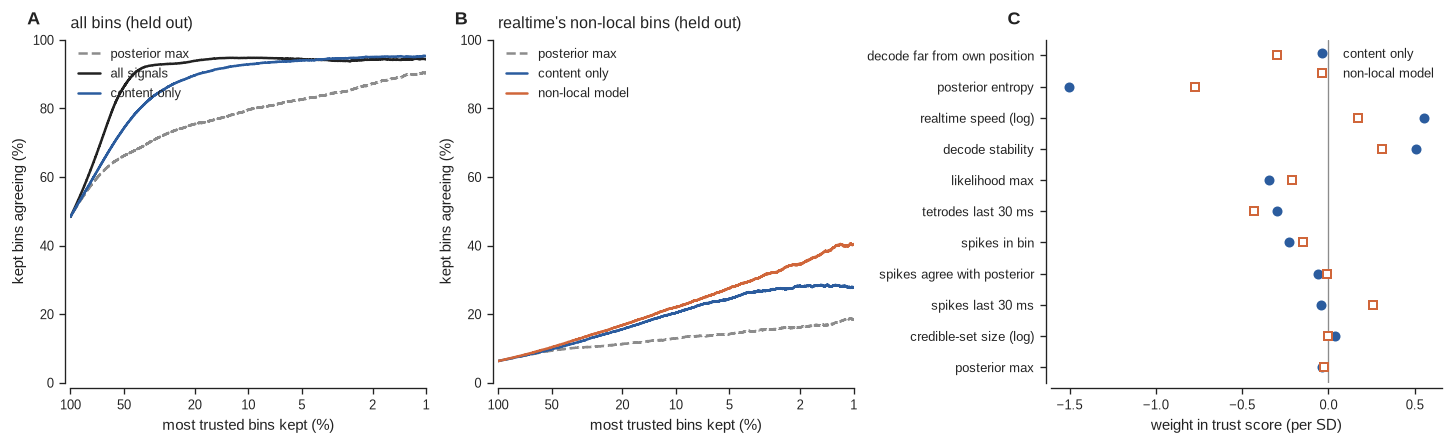

held-out comparison (AUC: 0.5 = no better than chance at ranking, 1 = perfect):


AUC  agree % in top 50%  \
bins                      score                                        
all bins                  all signals      0.938              86.398   
                          content only     0.830              74.288   
                          non-local model  0.906              81.277   
                          posterior max    0.742              66.193   
realtime's non-local bins all signals      0.740              10.184   
                          content only     0.721               9.758   
                          non-local model  0.754              10.355   
                          posterior max    0.666               9.340   
running                   all signals      0.928              90.348   
                          content only     0.809              79.059   
                          non-local model  0.898              86.961   
                          posterior max    0.717              71.294   
still                     all signals      0.937              81.772   
                          content only     0.834              70.290   
                          non-local model  0.910              76.334   
                          posterior max    0.751              63.201   

                                           agree % in top 20%  \
bins                      score                                 
all bins                  all signals                  93.875   
                          content only                 89.643   
                          non-local model              94.984   
                          posterior max                75.450   
realtime's non-local bins all signals                  16.237   
                          content only                 15.594   
                          non-local model              16.777   
                          posterior max                11.287   
running                   all signals                  94.066   
                          content only                 91.887   
                          non-local model              95.792   
                          posterior max                79.764   
still                     all signals                  94.095   
                          content only                 86.463   
                          non-local model              95.526   
                          posterior max                70.711   

                                           agree % in top 5%  
bins                      score                               
all bins                  all signals                 94.409  
                          content only                93.982  
                          non-local model             97.636  
                          posterior max               82.582  
realtime's non-local bins all signals                 24.753  
                          content only                24.455  
                          non-local model             27.584  
                          posterior max               14.137  
running                   all signals                 94.792  
                          content only                94.736  
                          non-local model             97.472  
                          posterior max               85.547  
still                     all signals                 96.374  
                          content only                89.784  
                          non-local model             98.647  
                          posterior max               79.626

weights (per SD) of every model:


,all signals,content only,non-local model
credible-set size (log),0.162,0.040,-0.004
decode far from own position,-2.531,NaN,-0.301
decode stability,0.445,0.510,0.312
likelihood max,-0.348,-0.346,-0.212
posterior entropy,-0.969,-1.505,-0.771
posterior max,0.249,-0.036,-0.026
realtime speed (log),-0.289,0.555,0.174
spikes agree with posterior,-0.045,-0.062,-0.011
spikes in bin,-0.209,-0.229,-0.146
spikes last 30 ms,-0.030,-0.044,0.255


In [12]:
# tetrodes contributing spikes in the 30 ms window ending at each bin's right edge (encoder records, sent to decoder)
enc = pd.read_hdf(sorted(glob.glob(f'{RUN_DIR}/*.rec_merged.h5'))[-1], 'rec_3')
enc = enc.loc[enc.sent_to_decoder, ['timestamp', 'elec_grp_id']]
win = int(0.030 * FS)
right = pairs.bin_r.to_numpy()
n_trodes = np.zeros(len(pairs), int)
for g_, ts in enc.groupby('elec_grp_id').timestamp:
    ts = np.sort(ts.to_numpy())
    n_trodes += (np.searchsorted(ts, right) - np.searchsorted(ts, right - win)) > 0
del enc

rd = pairs.rt_dec.to_numpy()
stab = np.zeros(len(pairs), int)
for lag in range(1, 5):
    stab[lag:] += hex_steps(rd[lag:], rd[:-lag]).clip(0) <= AGREE_TOL
trk_cm = px2cm(np.c_[pairs.trk_x, pairs.trk_y])

FEAT = pd.DataFrame({
    'posterior max'              : pairs.post_max,
    'posterior entropy'          : pairs.entropy,
    'credible-set size (log)'    : np.log(pairs.cred_post),
    'likelihood max'             : pairs.lik_max,
    'spikes in bin'              : pairs.spikes,
    'spikes last 30 ms'          : pairs.spk_recent,
    'tetrodes last 30 ms'        : n_trodes,
    'decode stability'           : stab,
    'spikes agree with posterior': (hex_steps(pairs.rt_lik, pairs.rt_dec).clip(0) <= AGREE_TOL).astype(float),
    'realtime speed (log)'       : np.log1p(pairs.rt_vel.clip(lower=0)),
    'decode far from own position': np.log1p(np.hypot(pairs.rt_x - trk_cm[:, 0], pairs.rt_y - trk_cm[:, 1])),
})
y = agree.astype(float)

def fit_logit(X, y, iters=40, ridge=1e-6):
    X1 = np.c_[np.ones(len(X)), X]
    b = np.zeros(X1.shape[1])
    for _ in range(iters):
        p = 1 / (1 + np.exp(-X1 @ b))
        H = X1.T @ (X1 * (p * (1 - p))[:, None]) + ridge * len(y) * np.eye(X1.shape[1])
        step = np.linalg.solve(H, X1.T @ (y - p) - ridge * len(y) * b)
        b += step
        if np.abs(step).max() < 1e-8:
            break
    return b

def fit_score(cols, fit_on):
    # fit on the training chunks within `fit_on`; return weights (per SD) and a score for every bin
    m = fit_on & train
    mu, sd = FEAT.loc[m, cols].mean(), FEAT.loc[m, cols].std()
    Zc = ((FEAT[cols] - mu) / sd).to_numpy()
    b = fit_logit(Zc[m], y[m])
    return pd.Series(b[1:], index=cols), np.c_[np.ones(len(Zc)), Zc] @ b

ALL_COLS = list(FEAT.columns)
CONTENT  = [c for c in ALL_COLS if c != 'decode far from own position']
everything = np.ones(len(pairs), bool)
MODELS = {'all signals'        : fit_score(ALL_COLS, everything),
          'content only'       : fit_score(CONTENT, everything),
          'non-local model'    : fit_score(ALL_COLS, rt_nl)}          # trained on realtime's non-local bins only

def auc(x, yy):
    r = rankdata(np.asarray(x, float)); yy = np.asarray(yy, bool)
    n1, n0 = yy.sum(), (~yy).sum()
    return (r[yy].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

def top_curve(s, m):
    o = np.argsort(-s[m], kind='stable'); a = agree[m][o]
    kk = np.arange(1, len(a) + 1)
    return 100 * kk / len(a), 100 * np.cumsum(a) / kk

test = ~train
SCORES = {'posterior max': pm, **{k: v[1] for k, v in MODELS.items()}}
STYLE  = {'posterior max': (MUTED, '--'), 'all signals': (INK, '-'), 'content only': (RT, '-'),
          'non-local model': (OF, '-')}

fig, (a0, a1, a2) = plt.subplots(1, 3, figsize=(12, 3.6), width_ratios=[1, 1, 1.1])
for ax, mask, names, ttl in [(a0, test, ['posterior max', 'all signals', 'content only'], 'all bins (held out)'),
                             (a1, test & rt_nl, ['posterior max', 'content only', 'non-local model'],
                              "realtime's non-local bins (held out)")]:
    for nm in names:
        x_, y_ = top_curve(SCORES[nm], mask)
        ax.plot(x_, y_, color=STYLE[nm][0], ls=STYLE[nm][1], label=nm)
    ax.set_xscale('log'); ax.set_xlim(100, 1)
    ax.set_xticks([100, 50, 20, 10, 5, 2, 1], ['100', '50', '20', '10', '5', '2', '1']); ax.minorticks_off()
    ax.set_ylim(0, 100); ax.set_title(ttl)
    ax.set_xlabel('most trusted bins kept (%)'); ax.set_ylabel('kept bins agreeing (%)')
    ax.legend(loc='upper left')
w = pd.DataFrame({'content only': MODELS['content only'][0], 'non-local model': MODELS['non-local model'][0]})
w = w.loc[w['content only'].abs().sort_values().index.union(w.index[w['content only'].isna()], sort=False)]
yy = np.arange(len(w))
a2.axvline(0, color=MUTED, lw=0.8)
a2.plot(w['content only'], yy, 'o', color=RT, ms=5, label='content only')
a2.plot(w['non-local model'], yy, 's', color=OF, ms=5, mfc='white', mew=1.2, label='non-local model')
a2.set_yticks(yy, w.index); a2.set_xlabel('weight in trust score (per SD)')
a2.legend(loc='upper right')
letter([a0, a1, a2])
show(fig, 'trust07_beyond_posterior_max')

rows = []
for nm, s_ in SCORES.items():
    for lab, m, _, _ in GROUPS + [("realtime's non-local bins", rt_nl, None, None)]:
        mt = m & test
        _, cur = top_curve(s_, mt)
        n_ = mt.sum()
        rows.append({'score': nm, 'bins': lab, 'AUC': auc(s_[mt], agree[mt]),
                     **{f'agree % in top {q}%': cur[int(n_ * q / 100) - 1] for q in (50, 20, 5)}})
print('held-out comparison (AUC: 0.5 = no better than chance at ranking, 1 = perfect):')
display(pd.DataFrame(rows).set_index(['bins', 'score']).sort_index().round(3))
print('weights (per SD) of every model:')
display(pd.DataFrame({k: v[0] for k, v in MODELS.items()}).round(3))

**Figure 7.** Held-out "keep the most trusted X%" curves. **A**, All bins: posterior max alone vs trust scores
with all signals and without the rat's own position. **B**, Realtime's non-local bins: posterior max vs the content-only
score and a score trained on non-local bins. **C**, Weights of the two content scores (per SD; right of 0 = more trust).

**Takeaway.**

- **The all-signals score looks spectacular (held-out AUC 0.94, against 0.72 for posterior max) but mostly cheats.**
  Its biggest weight is "decode far from own position", i.e. it trusts realtime when the decode is where the rat
  already is. True most of the time, and useless for non-local content.
- **Without that shortcut it is still much better than posterior max.** The content-only score has AUC 0.84. Its top
  20% of bins agree 88% (posterior max: 70%): 91% vs 78% while running, 84% vs 63% at rest.
- **What it relies on:** a sharply peaked posterior (low entropy), a decode that stayed within 1 hex over the last 4
  bins, and higher realtime speed. More spikes and more tetrodes in the window *lower* trust slightly, consistent with
  busy rest bins being the hardest.
- **On non-local bins the gain is real but small:** AUC 0.76 vs 0.64. The top 5% of non-local bins agree 27%
  (posterior max: 11%), the top 1% about 43%.
- **One session, alternating chunks:** these scores need checking on other sessions before they become a condition.

## 10 · Threshold menu — which threshold for which objective?

For each objective, the smallest posterior-max threshold that reaches the target is **chosen on the training chunks**
(fine grid, step 0.01) and then **checked on the held-out chunks**: the table reports the held-out value and how much
data survives. "not reached" = no threshold up to 0.95 reaches the target on the training chunks.

In [13]:
FINE = np.round(np.arange(0, 0.951, 0.01), 2)
r_dw, o_dw, rec_dw = ES['dwell', 'tables']
ev_train = ((r_dw.block.to_numpy() * BLOCK_S / 60) // SPLIT_MIN % 2 == 0)        # same 2-minute chunks as the bins

def metric_fns(name):
    # returns f(mask_of_units, t) -> (value %, kept %) for one objective
    if name.startswith('agreement'):
        grp = {'agreement, all bins': GROUPS[0][1], 'agreement, running': GROUPS[1][1], 'agreement, still': GROUPS[2][1]}[name]
        def f(split, t):
            m = grp & split
            k_ = m & (pm >= t)
            return 100 * agree[k_].mean() if k_.sum() >= MIN_N else np.nan, 100 * k_.sum() / m.sum()
        return f, train, ~train
    if name == 'non-local precision, bins':
        def f(split, t):
            m = rt_nl & split; k_ = m & (pm >= t)
            return 100 * agree[k_].mean() if k_.sum() >= MIN_N else np.nan, 100 * k_.sum() / m.sum()
        return f, train, ~train
    if name == 'non-local precision, dwell events':
        rpm_, rag_ = r_dw.mean_pm.to_numpy(), r_dw.agree.to_numpy()
        def f(split, t):
            k_ = split & (rpm_ >= t)
            return 100 * rag_[k_].mean() if k_.sum() >= 30 else np.nan, 100 * k_.sum() / split.sum()
        return f, ev_train, ~ev_train

OBJ = [('agreement, all bins', [60, 70, 80]), ('agreement, running', [60, 70, 80]), ('agreement, still', [50, 60, 70]),
       ('non-local precision, bins', [15, 20, 30]), ('non-local precision, dwell events', [20, 30, 40])]
rows = []
for name, targets in OBJ:
    f, tr, te = metric_fns(name)
    tr_vals = np.array([f(tr, t)[0] for t in FINE])
    for target in targets:
        hit = np.flatnonzero(tr_vals >= target)
        if not len(hit):
            rows.append({'objective': name, 'target %': target, 'threshold': 'not reached'}); continue
        t = FINE[hit[0]]
        v, kept = f(te, t)
        rows.append({'objective': name, 'target %': target, 'threshold': t,
                     'held-out value %': round(v, 1), 'held-out kept %': round(kept, 1)})
MENU = pd.DataFrame(rows).set_index(['objective', 'target %'])
display(MENU)

threshold  held-out value %  \
objective                         target %                                  
agreement, all bins               60               0.25              63.4   
                                  70               0.43              73.0   
                                  80               0.77              82.2   
agreement, running                60               0.18              61.3   
                                  70               0.32              71.4   
                                  80               0.57              80.9   
agreement, still                  50               0.18              55.8   
                                  60               0.32              64.8   
                                  70                0.6              73.7   
non-local precision, bins         15               0.82              16.7   
                                  20        not reached               NaN   
                                  30        not reached               NaN   
non-local precision, dwell events 20        not reached               NaN   
                                  30        not reached               NaN   
                                  40        not reached               NaN   

                                            held-out kept %  
objective                         target %                   
agreement, all bins               60                   60.2  
                                  70                   27.4  
                                  80                    5.6  
agreement, running                60                   83.9  
                                  70                   49.8  
                                  80                   16.2  
agreement, still                  50                   71.6  
                                  60                   38.0  
                                  70                   10.5  
non-local precision, bins         15                    1.5  
                                  20                    NaN  
                                  30                    NaN  
non-local precision, dwell events 20                    NaN  
                                  30                    NaN  
                                  40                    NaN

**Takeaway.**

- **Running:** 60% agreement at ≥ 0.18 (keeps 78% of running bins), 70% at ≥ 0.34 (keeps 42%), 80% at ≥ 0.64 (keeps 11%).
- **Still:** 50% at ≥ 0.24 (keeps 46%), 60% at ≥ 0.48 (keeps 16%), 70% at ≥ 0.82 (keeps 5%).
- **All bins:** 60% at ≥ 0.29, 70% at ≥ 0.56; 80% is not reachable.
- **Non-local:** bin precision reaches 15% only at ≥ 0.93 (keeping under 1% of non-local bins), and neither bin nor
  event precision reaches 20% at any threshold.
- **Held-out values land on target**, so these thresholds aren't overfitted to this session's chunks. They are still
  fitted to *this session*, though.
- **Practical reading:** posterior max is a usable condition for *local* decoding, best combined with a running/still
  split. For non-local (replay-like) content, a threshold alone is not enough. The content-only score (§9), a per-hex
  whitelist (§8), and the decoder settings from `online_offline_comparison.ipynb` (prior, preload, barriers) are the
  next levers.

## 11 · Timing of non-local representation — who has more, and do they happen at the same time?

The plan is to **trigger the laser whenever the realtime decoder reports non-local representation**. Two questions
decide whether that works, and this section answers both **ignoring where each decoder points** (§4–§5 add the
same-place requirement):

1. **Who has more non-local representation**, realtime or offline? (time spent non-local, and events per minute)
2. **Do they happen at the same time?** When realtime is non-local (and passes the threshold), is offline non-local
   too? And how much of offline's non-local time does realtime cover?

**Chance level.** Realtime shifted by half the session against offline. That keeps how often, and in what stretches,
each decoder goes non-local, but breaks any real timing link. An overlap only means something above this line.

**Events = the "trigger" view.** A trigger is one realtime non-local stretch (a **parent interval**: > 20 cm from the
rat for > 20 ms), kept if its mean posterior max ≥ the threshold. Dwell events are reported alongside in the table.

,all bins,running,still
realtime: % of bins non-local,51.13,39.70,59.94
offline: % of bins non-local,12.37,10.78,13.66
realtime / offline,4.13,3.68,4.39


per minute  median ms  \
events                                 decoder                           
non-local stretches (parent intervals) realtime       152.0       60.0   
                                       offline         30.9      106.0   
dwell events                           realtime       393.2       36.0   
                                       offline         41.7       78.0   

                                                 % of session covered  
events                                 decoder                         
non-local stretches (parent intervals) realtime                  42.2  
                                       offline                   11.9  
dwell events                           realtime                  30.3  
                                       offline                   11.6

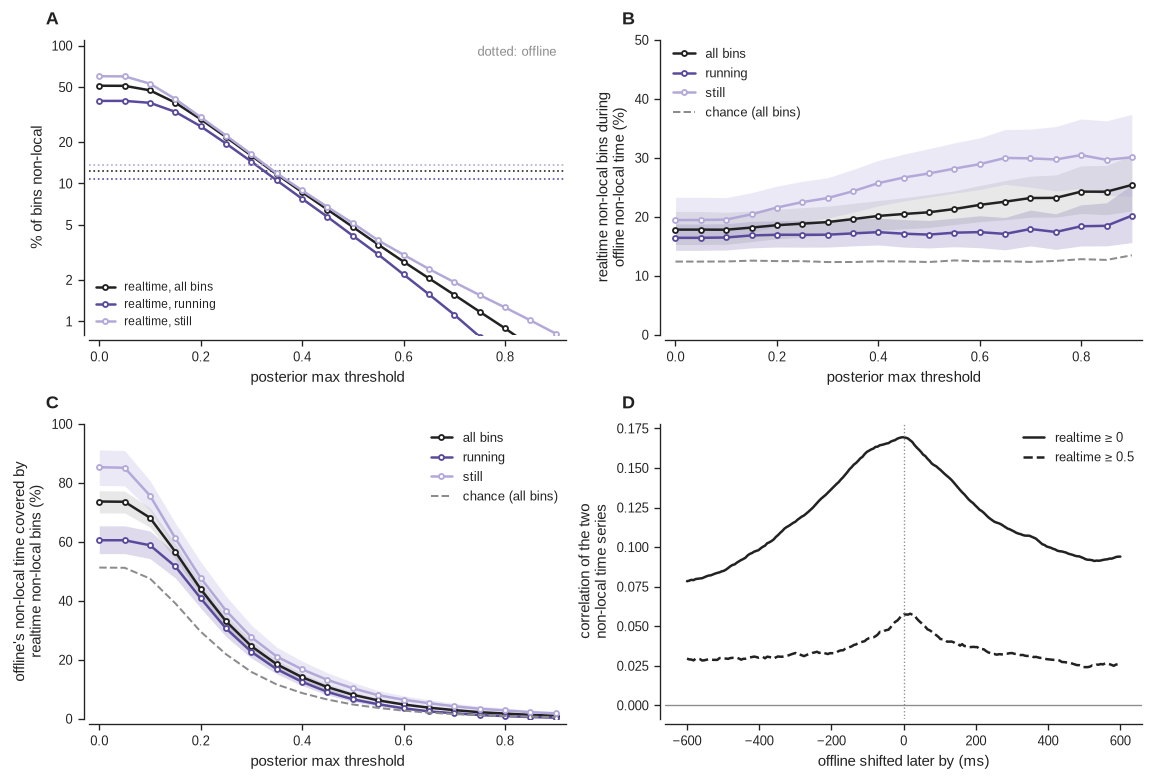

cross-correlation peak r = 0.169 at +0 ms (r at 0 ms = 0.169)
all bins, place ignored:


,"realtime non-local, % of all bins",offline also non-local %,chance %,offline non-local time covered %,chance cover %
posterior max >=,,,,,
0.0,51.1,17.8,12.4,73.7,51.3
0.2,29.2,18.6,12.5,43.9,29.5
0.3,15.9,19.1,12.3,24.6,15.9
0.4,8.6,20.1,12.4,14.1,8.7
0.5,4.8,20.8,12.3,8.1,4.8
0.6,2.7,22.0,12.5,4.8,2.7
0.7,1.6,23.2,12.3,2.9,1.6


In [14]:
half = len(pairs) // 2
rt_nl_s, pm_s = np.roll(rt_nl, half), np.roll(pm, half)       # realtime shifted by half the session (chance level)
dur_min = len(pairs) * BIN_S / 60
sess_s  = len(pairs) * BIN_S

# ---- how much non-local representation each decoder has
amt = {}
for lab, m, _, _ in GROUPS:
    amt[lab] = {'realtime: % of bins non-local': 100 * rt_nl[m].mean(), 'offline: % of bins non-local': 100 * of_nl[m].mean(),
                'realtime / offline': rt_nl[m].mean() / of_nl[m].mean()}
display(pd.DataFrame(amt).round(2))
rows = []
for kind, nm in [('parent', 'non-local stretches (parent intervals)'), ('dwell', 'dwell events')]:
    for src in ['realtime', 'offline']:
        e_ = EV[src][kind]
        rows.append({'events': nm, 'decoder': src, 'per minute': len(e_) / dur_min, 'median ms': 1e3 * e_.duration.median(),
                     '% of session covered': 100 * e_.duration.sum() / sess_s})
display(pd.DataFrame(rows).set_index(['events', 'decoder']).round(1))

# ---- bin level, place ignored
TIM = {}
for lab, m, _, _ in GROUPS:
    TIM[lab, 'share']     = pd.Series([100 * (m & rt_nl & (pm >= t)).sum() / m.sum() for t in THRESH], index=THRESH)
    TIM[lab, 'precision'] = thr_curve(blk, lambda t: m & rt_nl & (pm >= t) & of_nl, lambda t: m & rt_nl & (pm >= t))
    TIM[lab, 'recall']    = thr_curve(blk, lambda t: m & of_nl & rt_nl & (pm >= t), lambda t: m & of_nl)
chance_p = pd.Series([100 * of_nl[rt_nl_s & (pm_s >= t)].mean() for t in THRESH], index=THRESH)
chance_r = pd.Series([100 * (of_nl & rt_nl_s & (pm_s >= t)).sum() / of_nl.sum() for t in THRESH], index=THRESH)

def xcorr(a, b, lags):
    # Pearson correlation between a(t) and b(t + lag)
    a = a.astype(float) - a.mean(); b = b.astype(float) - b.mean()
    n = len(a)
    return np.array([np.dot(a[max(0, -l):n - max(0, l)], b[max(0, l):n - max(0, -l)]) / np.sqrt(np.dot(a, a) * np.dot(b, b))
                     for l in lags])
LAGS = np.arange(-100, 101)                                   # bins (6 ms): ±600 ms

fig, axes = plt.subplots(2, 2, figsize=(9.5, 6.4))
(a0, a1), (a2, a3) = axes
for lab, m, c, ba in GROUPS:
    a0.plot(THRESH, TIM[lab, 'share'], color=c, marker='o', ms=3, mfc='white', mew=1.1, label=f'realtime, {lab}')
    a0.axhline(100 * of_nl[m].mean(), color=c, lw=1, ls=':')
    ci_line(a1, TIM[lab, 'precision'].index, TIM[lab, 'precision'], c, label=lab, band_alpha=ba, ms=3)
    ci_line(a2, TIM[lab, 'recall'].index, TIM[lab, 'recall'], c, label=lab, band_alpha=ba, ms=3)
a0.annotate('dotted: offline', xy=(0.98, 0.98), xycoords='axes fraction', ha='right', va='top', fontsize=7.5, color=MUTED)
thr_axes(a0, '% of bins non-local', ylim=None); log_pct_axis(a0)
a0.legend(loc='lower left', fontsize=7)
a1.plot(THRESH, chance_p, color=MUTED, lw=1.2, ls='--', label='chance (all bins)')
thr_axes(a1, 'realtime non-local bins during\noffline non-local time (%)', ylim=(0, 50))
a1.legend(loc='upper left')
a2.plot(THRESH, chance_r, color=MUTED, lw=1.2, ls='--', label='chance (all bins)')
thr_axes(a2, "offline's non-local time covered by\nrealtime non-local bins (%)")
a2.legend(loc='upper right')
for t, ls in [(0.0, '-'), (0.5, '--')]:
    a3.plot(LAGS * BIN_S * 1e3, xcorr(rt_nl & (pm >= t), of_nl, LAGS), color=INK, ls=ls, label=f'realtime ≥ {t:g}')
a3.axvline(0, color=MUTED, lw=0.8, ls=':'); a3.axhline(0, color=MUTED, lw=0.8)
a3.set_xlabel('offline shifted later by (ms)'); a3.set_ylabel('correlation of the two\nnon-local time series')
a3.legend(loc='upper right')
letter(axes)
show(fig, 'trust08_nonlocal_timing_bins')

cc0 = xcorr(rt_nl, of_nl, LAGS)
print(f'cross-correlation peak r = {cc0.max():.3f} at {LAGS[cc0.argmax()] * BIN_S * 1e3:+.0f} ms (r at 0 ms = {cc0[LAGS == 0][0]:.3f})')
rows = []
for t in [0, .2, .3, .4, .5, .6, .7]:
    k_ = rt_nl & (pm >= t)
    rows.append({'posterior max >=': t, 'realtime non-local, % of all bins': 100 * k_.mean(),
                 'offline also non-local %': 100 * of_nl[k_].mean(), 'chance %': chance_p[t],
                 'offline non-local time covered %': 100 * (of_nl & k_).sum() / of_nl.sum(), 'chance cover %': chance_r[t]})
print('all bins, place ignored:')
display(pd.DataFrame(rows).set_index('posterior max >=').round(1))

**Figure 8.** Non-local representation in time, place ignored. **A**, Share of bins in which realtime is
non-local and passes the threshold (log axis), for all, running and still bins; dotted lines: offline's non-local
share in the same bins. **B**, Of those realtime bins, the share during offline non-local time. **C**, Of offline's
non-local time, the share covered by realtime non-local bins that pass the threshold. Dashed grey: chance (realtime
shifted by half the session). **D**, Correlation between the two non-local time series as offline is shifted in
time, for all realtime non-local bins and for those ≥ 0.5. Bands: 95% CI.

**Takeaway.**

- **Realtime has far more non-local representation:** 55% of bins against offline's 12% (4.5×). At rest it is 66% vs
  14%, while running 42% vs 11%. Only at a threshold of about 0.35 does realtime's non-local share drop to offline's
  level.
- **When realtime is non-local, offline usually isn't:** offline is non-local at the same moment only 17% of the time
  with no threshold, against 12.5% by chance. Thresholds raise that slowly: 19% at ≥ 0.5, 21% at ≥ 0.8. At rest it
  reaches about 26%; while running it stays near 16%.
- **The coverage looks high, but most of it is chance.** Realtime's non-local bins cover 76% of offline's non-local
  time with no threshold, but chance alone gives 56%, because realtime is non-local half the time. At ≥ 0.3: 22% vs
  15% by chance.
- **No lead or lag.** The two series line up best at 0 ms, but the correlation is weak: 0.16, and 0.05 for bins
  ≥ 0.5. When they are non-local together, it is at the same moment, not one decoder running ahead of the other.

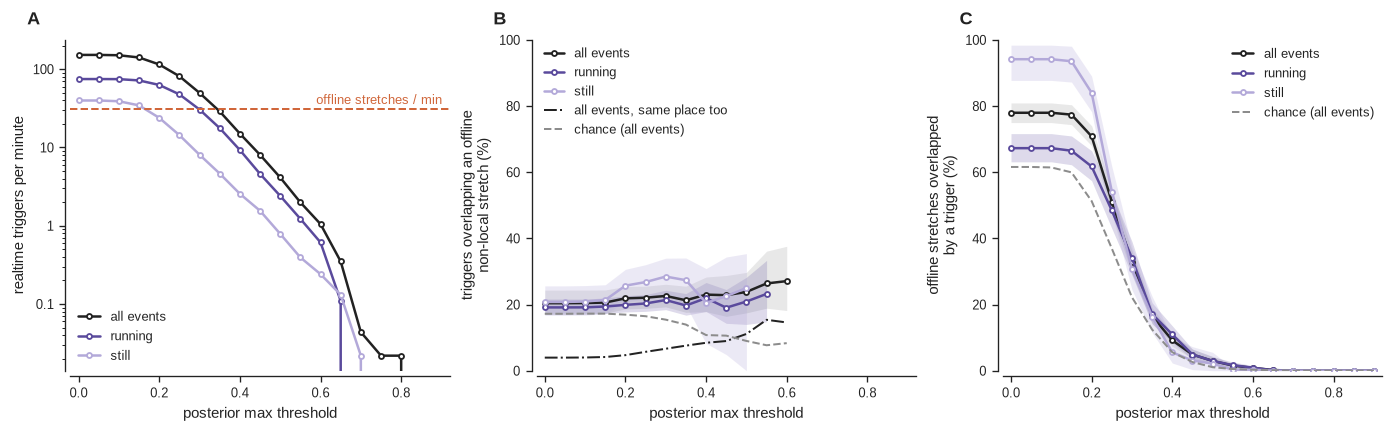

trigger view: one trigger per kept realtime event (parent = non-local stretch; dwell = dwell segment)


triggers / min  % of session in kept events  \
events mean posterior max >=                                                
parent 0.0                             152.0                         42.2   
       0.2                             114.8                         33.5   
       0.3                              49.7                         11.1   
       0.4                              15.0                          2.0   
       0.5                               4.1                          0.3   
       0.6                               1.0                          0.1   
dwell  0.0                             393.2                         30.3   
       0.2                             258.8                         21.2   
       0.3                             126.6                         10.8   
       0.4                              50.7                          4.3   
       0.5                              16.2                          1.2   
       0.6                               4.7                          0.3   

                              overlap offline in time %  chance %  \
events mean posterior max >=                                        
parent 0.0                                         20.4      17.2   
       0.2                                         21.9      16.9   
       0.3                                         22.6      15.4   
       0.4                                         23.0      10.8   
       0.5                                         23.8       9.0   
       0.6                                         27.1       8.3   
dwell  0.0                                         20.1      13.5   
       0.2                                         21.1      13.7   
       0.3                                         22.7      13.8   
       0.4                                         25.0      13.7   
       0.5                                         28.2      12.3   
       0.6                                         32.7      11.2   

                              same place too %  offline events overlapped %  
events mean posterior max >=                                                 
parent 0.0                                 4.0                         78.0  
       0.2                                 4.7                         70.8  
       0.3                                 6.6                         32.8  
       0.4                                 8.4                          9.2  
       0.5                                11.1                          3.0  
       0.6                                14.6                          0.8  
dwell  0.0                                 4.0                         72.4  
       0.2                                 5.2                         65.0  
       0.3                                 7.1                         43.7  
       0.4                                 9.8                         22.4  
       0.5                                12.8                          9.4  
       0.6                                16.8                          3.3

In [15]:
def overlaps(sa, ea, sb, eb):
    # for each interval a, does it overlap any interval b? (b sorted and non-overlapping)
    k = np.searchsorted(sb, ea, side='right') - 1
    return (k >= 0) & (eb[k.clip(0)] >= sa)

def shifted(e_):
    # the same events moved by half the session, wrapped around, re-sorted (chance level)
    t0 = tb[0]
    s_ = (e_.start_time.to_numpy() - t0 + sess_s / 2) % sess_s + t0
    d_ = e_.end_time.to_numpy() - e_.start_time.to_numpy()
    o_ = np.argsort(s_)
    return s_[o_], (s_ + d_)[o_], o_

TRIG = {}
for kind in ['parent', 'dwell']:
    r, o, recovered = ES[kind, 'tables']
    rte, ofe = EV['realtime'][kind], EV['offline'][kind]
    rs, re_, os_, oe = (rte.start_time.to_numpy(), rte.end_time.to_numpy(),
                        ofe.start_time.to_numpy(), ofe.end_time.to_numpy())
    hit = overlaps(rs, re_, os_, oe)                       # realtime event overlaps an offline event in time
    ss, se, order = shifted(rte)
    hit_s = overlaps(ss, se, os_, oe)                      # same, shifted (aligned with `order`)
    rpm, rag = r.mean_pm.to_numpy(), r.agree.to_numpy()
    def covered(t, s=rs, e=re_, keep=None, rpm=rpm, os_=os_, oe=oe, n_of=len(ofe)):
        # offline events overlapped by a kept realtime event (variables bound now, not at call time)
        k_ = rpm >= t if keep is None else keep(t)
        return overlaps(os_, oe, s[k_], e[k_]) if k_.any() else np.zeros(n_of, bool)
    TRIG[kind] = dict(r=r, o=o, hit=hit, hit_s=hit_s, order=order, ss=ss, se=se, rpm=rpm, rag=rag, covered=covered)

# figure: the trigger view, parent stretches
T_ = TRIG['parent']; r, o = T_['r'], T_['o']
rb, ob = r.block.to_numpy(), o.block.to_numpy()
fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.5))
a0, a1, a2 = axes
for (lab, m, c, ba), (_, mo, _, _) in zip(event_groups(r.speed.to_numpy()), event_groups(o.speed.to_numpy())):
    per_min = [(m & (T_['rpm'] >= t)).sum() / dur_min for t in THRESH]
    a0.plot(THRESH, per_min, color=c, marker='o', ms=3, mfc='white', mew=1.1, label=lab)
    cv = thr_curve(rb, lambda t: m & (T_['rpm'] >= t) & T_['hit'], lambda t: m & (T_['rpm'] >= t), min_n=30)
    ci_line(a1, cv.index, cv, c, label=lab, band_alpha=ba, ms=3)
    cv = thr_curve(ob, lambda t: mo & T_['covered'](t), lambda t: mo, min_n=30)
    ci_line(a2, cv.index, cv, c, label=lab, band_alpha=ba, ms=3)
a0.axhline(len(EV['offline']['parent']) / dur_min, color=OF, lw=1.2, ls='--')
a0.annotate('offline stretches / min', xy=(0.98, len(EV['offline']['parent']) / dur_min), xycoords=('axes fraction', 'data'),
            xytext=(0, 3), textcoords='offset points', ha='right', fontsize=7.5, color=OF)
a0.set_yscale('log'); a0.yaxis.set_major_formatter(PLAIN)
thr_axes(a0, 'realtime triggers per minute', ylim=None)
a0.legend(loc='lower left')
kept_any = lambda t: T_['rpm'] >= t
same = pd.Series([100 * T_['rag'][kept_any(t)].mean() if kept_any(t).sum() >= 30 else np.nan for t in THRESH], index=THRESH)
chance_e = pd.Series([100 * T_['hit_s'][(T_['rpm'][T_['order']] >= t)].mean() if kept_any(t).sum() >= 30 else np.nan
                      for t in THRESH], index=THRESH)
a1.plot(THRESH, same, color=INK, ls='-.', lw=1.2, label='all events, same place too')
a1.plot(THRESH, chance_e, color=MUTED, ls='--', lw=1.2, label='chance (all events)')
thr_axes(a1, 'triggers overlapping an offline\nnon-local stretch (%)')
a1.legend(loc='upper left', fontsize=7.5)
chance_c = pd.Series([100 * T_['covered'](t, s=T_['ss'], e=T_['se'], keep=lambda t: T_['rpm'][T_['order']] >= t).mean()
                      for t in THRESH], index=THRESH)
a2.plot(THRESH, chance_c, color=MUTED, ls='--', lw=1.2, label='chance (all events)')
thr_axes(a2, "offline stretches overlapped\nby a trigger (%)")
a2.legend(loc='upper right')
letter(axes)
show(fig, 'trust09_nonlocal_timing_triggers')

rows = []
for kind in ['parent', 'dwell']:
    T_ = TRIG[kind]
    for t in [0, .2, .3, .4, .5, .6]:
        k_ = T_['rpm'] >= t
        if k_.sum() == 0:
            continue
        rows.append({'events': kind, 'mean posterior max >=': t, 'triggers / min': k_.sum() / dur_min,
                     '% of session in kept events': 100 * T_['r'].assign(d=EV['realtime'][kind].duration.to_numpy()).d[k_].sum() / sess_s,
                     'overlap offline in time %': 100 * T_['hit'][k_].mean(),
                     'chance %': 100 * T_['hit_s'][T_['rpm'][T_['order']] >= t].mean(),
                     'same place too %': 100 * T_['rag'][k_].mean(),
                     'offline events overlapped %': 100 * T_['covered'](t).mean()})
print('trigger view: one trigger per kept realtime event (parent = non-local stretch; dwell = dwell segment)')
display(pd.DataFrame(rows).set_index(['events', 'mean posterior max >=']).round(1))

**Figure 9.** The trigger view: one trigger per realtime non-local stretch (parent interval) whose mean
posterior max passes the threshold, grouped by the rat's mean speed during the stretch. **A**, Triggers per minute (log
axis); dashed orange: offline's non-local stretches per minute. **B**, Share of triggers that overlap an offline
non-local stretch in time; dash-dot: overlap *and* same place (within 1 hex); dashed grey: chance. **C**, Share of
offline's non-local stretches overlapped by a trigger; dashed grey: chance. Bands: 95% CI.

**Takeaway.**

- **With no threshold, "fire on every realtime non-local stretch" means 187 triggers a minute** (offline has 31
  stretches a minute), and the kept stretches cover 45% of the session. The laser would be on almost half the time.
- **Almost none of that timing is real.** 19% of triggers overlap an offline non-local stretch, against 17% by chance,
  and only 3% also point to the same place. The trigger overlaps 81% of offline's stretches only because it fires so
  often (67% by chance).
- **A threshold makes triggers rarer and a little more meaningful.** At ≥ 0.3: 50 a minute (close to offline's rate),
  21% overlapping (chance 15%). At ≥ 0.5: 4 a minute, 28% overlapping (chance 12%). But by then only 9% point to the
  same place and only 3% of offline's stretches are caught.
- **Dwell events tell the same story:** overlap goes from 19% to 27% between no threshold and ≥ 0.5, against 13% by
  chance.
- **Bottom line:** in this run, a realtime non-local trigger would mostly fire at moments offline considers local. The
  threshold trades rate for a modest gain and can't fix that. The fix has to come from the decoder settings (prior,
  preload, barriers) before this trigger is worth running.

### 11b · A looser overlap rule: one realtime non-local bin is enough

Figure 9 asked for a whole realtime non-local *stretch* (> 20 ms, mean posterior max ≥ t) to overlap an offline
stretch. Here the bar is lower: **an offline non-local event counts as overlapped if at least one realtime bin inside
it is non-local and has posterior max ≥ t.** That bin is the moment a bin-triggered laser would fire.

- **A — recall, looser rule:** of offline's non-local stretches, the share containing at least one such realtime bin.
- **B — the trigger's side:** of the realtime non-local bins ≥ t (each one a possible laser pulse), the share that fall
  inside an offline non-local stretch.

As before: grey dashed = chance (realtime shifted by half the session); dash-dot = the bin is also within 1 hex of
offline's decode (same place), with its own chance line (grey dotted). Dwell events are in the table.

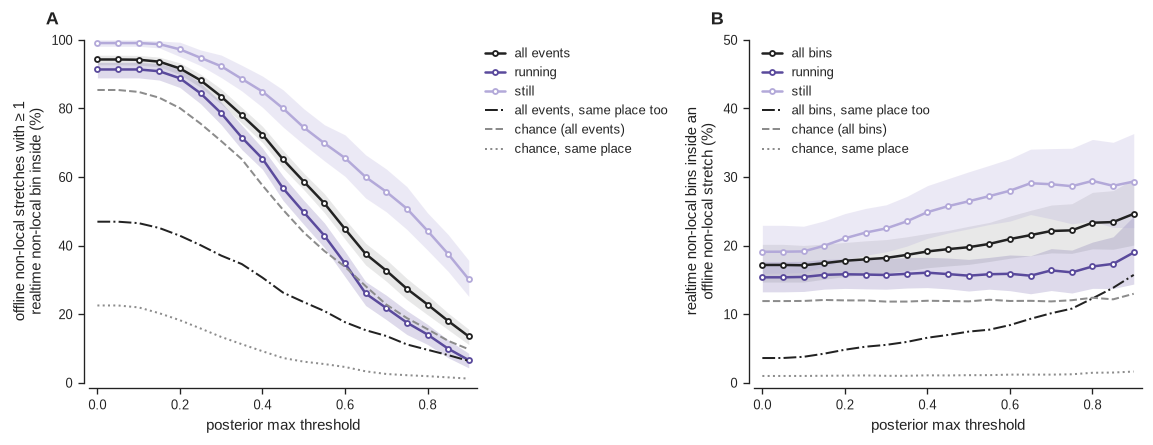

looser rule: one realtime non-local bin (posterior max >= t) inside the offline event is enough


offline events caught %  chance %  \
offline events posterior max >=                                      
parent         0.0                                  94.3      85.4   
               0.2                                  91.7      80.1   
               0.3                                  83.5      70.5   
               0.4                                  72.4      57.6   
               0.5                                  58.7      43.9   
               0.6                                  44.8      33.8   
               0.7                                  32.7      22.8   
dwell          0.0                                  94.1      82.9   
               0.2                                  90.3      76.7   
               0.3                                  80.3      66.0   
               0.4                                  67.7      52.4   
               0.5                                  53.6      39.1   
               0.6                                  39.4      28.8   
               0.7                                  27.9      19.0   

                                 caught, same place %  chance, same place %  \
offline events posterior max >=                                               
parent         0.0                               47.0                  22.5   
               0.2                               42.9                  18.2   
               0.3                               37.1                  13.3   
               0.4                               30.6                   9.2   
               0.5                               23.5                   6.1   
               0.6                               17.7                   4.6   
               0.7                               13.6                   2.5   
dwell          0.0                               39.6                  17.9   
               0.2                               35.6                  14.4   
               0.3                               30.5                  10.2   
               0.4                               24.8                   7.0   
               0.5                               19.0                   4.7   
               0.6                               14.1                   3.5   
               0.7                               10.6                   1.9   

                                 realtime bins / min  \
offline events posterior max >=                        
parent         0.0                            5113.2   
               0.2                            2924.8   
               0.3                            1591.9   
               0.4                             864.5   
               0.5                             483.5   
               0.6                             271.0   
               0.7                             155.8   
dwell          0.0                            5113.2   
               0.2                            2924.8   
               0.3                            1591.9   
               0.4                             864.5   
               0.5                             483.5   
               0.6                             271.0   
               0.7                             155.8   

                                 bins inside an offline event %  chance  %  \
offline events posterior max >=                                              
parent         0.0                                         17.2       11.9   
               0.2                                         17.8       12.0   
               0.3                                         18.2       11.8   
               0.4                                         19.1       12.0   
               0.5                                         19.8       11.9   
               0.6                                         20.9       11.9   
               0.7                                         22.1       11.9   
dwell          0.0                              

In [16]:
LOOSE = {}
for kind in ['parent', 'dwell']:
    ofe = EV['offline'][kind]
    of_id = bin_membership(ofe)                         # offline event containing each realtime bin (-1 = none)
    inside = of_id >= 0
    n_of = len(ofe)
    def caught(flag, of_id=of_id, n_of=n_of):
        # offline events with at least one flagged realtime bin inside
        return np.bincount(of_id[(of_id >= 0) & flag], minlength=n_of) > 0
    LOOSE[kind] = dict(of_id=of_id, inside=inside, caught=caught, o=ES[kind, 'tables'][1])

L = LOOSE['parent']; o = L['o']; ob = o.block.to_numpy()
flag   = lambda t: rt_nl & (pm >= t)
flag_s = lambda t: rt_nl_s & (pm_s >= t)
agree_s = hex_steps(np.roll(pairs.rt_dec.to_numpy(), half), pairs.of_dec).clip(0) <= AGREE_TOL   # same place, by chance

fig, (a0, a1) = plt.subplots(1, 2, figsize=(9.5, 3.6))
for lab, mo, c, ba in event_groups(o.speed.to_numpy()):
    cv = thr_curve(ob, lambda t: mo & L['caught'](flag(t)), lambda t: mo, min_n=30)
    ci_line(a0, cv.index, cv, c, label=lab, band_alpha=ba, ms=3)
a0.plot(THRESH, [100 * L['caught'](flag(t) & agree).mean() for t in THRESH], color=INK, ls='-.', lw=1.2,
        label='all events, same place too')
a0.plot(THRESH, [100 * L['caught'](flag_s(t)).mean() for t in THRESH], color=MUTED, ls='--', lw=1.2, label='chance (all events)')
a0.plot(THRESH, [100 * L['caught'](flag_s(t) & agree_s).mean() for t in THRESH], color=MUTED, ls=':', lw=1.2,
        label='chance, same place')
thr_axes(a0, "offline non-local stretches with ≥ 1\nrealtime non-local bin inside (%)")
a0.legend(loc='upper left', bbox_to_anchor=(1.0, 1.0), fontsize=7.5)

for lab, m, c, ba in GROUPS:
    cv = thr_curve(blk, lambda t: m & flag(t) & L['inside'], lambda t: m & flag(t))
    ci_line(a1, cv.index, cv, c, label=lab, band_alpha=ba, ms=3)
a1.plot(THRESH, [100 * (L['inside'] & agree)[flag(t)].mean() for t in THRESH], color=INK, ls='-.', lw=1.2,
        label='all bins, same place too')
a1.plot(THRESH, [100 * L['inside'][flag_s(t)].mean() for t in THRESH], color=MUTED, ls='--', lw=1.2, label='chance (all bins)')
a1.plot(THRESH, [100 * (L['inside'] & agree_s)[flag_s(t)].mean() for t in THRESH], color=MUTED, ls=':', lw=1.2,
        label='chance, same place')
thr_axes(a1, 'realtime non-local bins inside an\noffline non-local stretch (%)', ylim=(0, 50))
a1.legend(loc='upper left', fontsize=7.5)
letter([a0, a1])
show(fig, 'trust10_nonlocal_timing_loose')

rows = []
for kind in ['parent', 'dwell']:
    L_ = LOOSE[kind]
    for t in [0, .2, .3, .4, .5, .6, .7]:
        f, fs = flag(t), flag_s(t)
        rows.append({'offline events': kind, 'posterior max >=': t,
                     'offline events caught %': 100 * L_['caught'](f).mean(),
                     'chance %': 100 * L_['caught'](fs).mean(),
                     'caught, same place %': 100 * L_['caught'](f & agree).mean(),
                     'chance, same place %': 100 * L_['caught'](fs & agree_s).mean(),
                     'realtime bins / min': f.sum() / dur_min,
                     'bins inside an offline event %': 100 * L_['inside'][f].mean(),
                     'chance  %': 100 * L_['inside'][fs].mean(),
                     'inside, same place %': 100 * (L_['inside'] & agree)[f].mean(),
                     'chance, same place  %': 100 * (L_['inside'] & agree_s)[fs].mean()})
print('looser rule: one realtime non-local bin (posterior max >= t) inside the offline event is enough')
display(pd.DataFrame(rows).set_index(['offline events', 'posterior max >=']).round(1))

**Figure 10.** The looser overlap rule: one realtime non-local bin with posterior max ≥ t inside the offline
event is enough. **A**, Share of offline's non-local stretches containing at least one such bin, by the rat's mean speed
during the stretch; dash-dot: that bin is also within 1 hex of offline's decode. **B**, Share of those realtime bins
(each one a possible laser pulse) that fall inside an offline non-local stretch; dash-dot: inside *and* at the same
place. Grey dashed and dotted: chance for the plain and same-place versions. Bands: 95% CI.

**Takeaway.**

- **Almost every offline stretch gets "caught", but chance comes close.** With no threshold, 96.5% of offline's
  stretches contain a realtime non-local bin; at ≥ 0.3 it is 84%, at ≥ 0.5 59%. Chance gives 89%, 74% and 50%.
  Realtime has so many non-local bins (5,500 a minute with no threshold, 515 a minute at ≥ 0.5) that one landing inside
  a stretch by luck is easy. On timing alone it stays only 7–10 points above chance, and while the rat runs the curve
  sits on the chance line.
- **"Same place" is where the looser rule shows real signal.** At least one realtime bin points to offline's
  non-local place in 51% of offline's stretches with no threshold (chance 28%), 24% at ≥ 0.5 (chance 7%) and 14% at
  ≥ 0.7 (chance 3%). That is 2–4× chance, and the ratio grows with the threshold.
- **The trigger's side barely moves.** Of realtime's non-local bins, 16.5% fall inside an offline stretch with no
  threshold and 20% at ≥ 0.7 (chance 12%). Only 3% (no threshold) to 8% (≥ 0.7) are inside *and* at the same place
  (chance about 1%).
- **What it means:** realtime does reach offline's non-local content for at least a moment in a good share of offline's
  events, clearly above chance. But a laser fired on every confident non-local bin would still be wrong more than 90%
  of the time. A rule that waits for consistent evidence within a stretch (e.g. several bins pointing to the same
  non-local place) would be the natural next test.

### 11c · The looser rule in the 3 minutes after each barrier shift

The same analysis as 11b, restricted to **the 3 minutes after each of the 4 barrier shifts** (12 minutes in total),
and compared with the rest of the session. A barrier shift changes which routes exist, so this asks whether
realtime's non-local representation lines up with offline's any differently right after the maze changes.

- **Shift times** come from the stateScript log ("Barrier shifted"; its clock is Trodes time in ms, checked below:
  at port pokes the rat should be at a corner hex). The realtime decoder itself was never told about barriers.
- **Assignment:** realtime bins by their time; offline non-local stretches by their midpoint.
- **Chance is measured inside each period:** realtime is shifted by half the length of each post-shift window (90 s)
  and of each stretch in between, so each period is compared against its own realtime statistics.
- The first window (15.0–18.0 min) contains the start of the long pause at hex 11 described in
  `online_offline_comparison.ipynb` §13.

clock check: rat at a corner hex (1-3) at 100.0% of 389 port pokes
barrier shifts at 15.0, 25.4, 35.4, 41.1 min into the realtime record  ·  windows: the 3 min after each
post-shift windows: 26.2% of bins, 378 of 1416 offline non-local stretches (31.5/min vs 30.8/min elsewhere); realtime non-local in 53.4% of post-shift bins vs 50.3% elsewhere


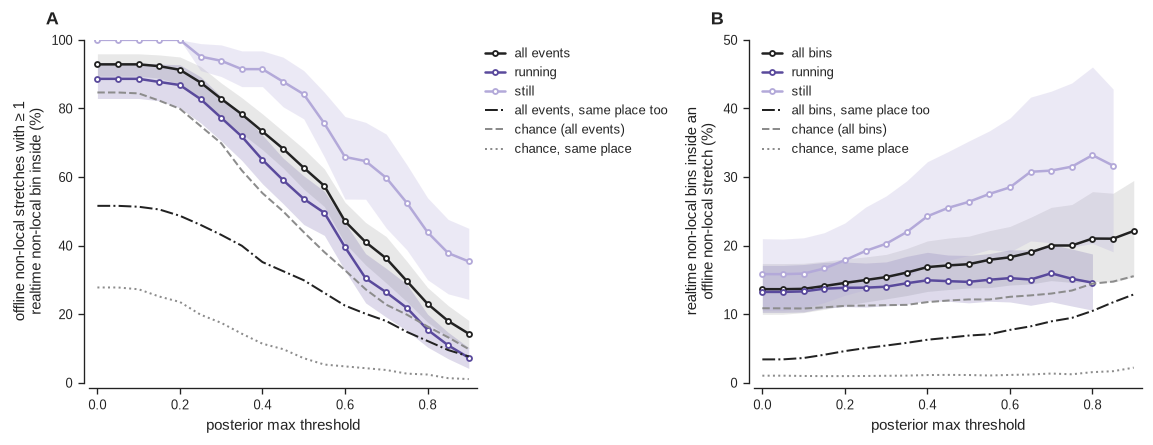

post-shift windows vs the rest of the session (parent stretches; chance measured within each period):


offline stretches caught %  chance %  \
period              posterior max >=                                         
3 min after a shift 0.0                                     92.9      84.7   
                    0.3                                     82.8      69.8   
                    0.5                                     62.7      43.9   
                    0.7                                     36.2      22.8   
rest of the session 0.0                                     94.8      85.1   
                    0.3                                     83.7      70.6   
                    0.5                                     57.2      46.1   
                    0.7                                     31.4      25.5   

                                      caught, same place %  \
period              posterior max >=                         
3 min after a shift 0.0                               51.6   
                    0.3                               43.1   
                    0.5                               29.9   
                    0.7                               18.0   
rest of the session 0.0                               45.3   
                    0.3                               34.9   
                    0.5                               21.2   
                    0.7                               12.0   

                                      chance, same place %  \
period              posterior max >=                         
3 min after a shift 0.0                               27.8   
                    0.3                               17.5   
                    0.5                                7.1   
                    0.7                                3.7   
rest of the session 0.0                               25.3   
                    0.3                               13.8   
                    0.5                                7.9   
                    0.7                                3.9   

                                      realtime bins inside %  chance  %  \
period              posterior max >=                                      
3 min after a shift 0.0                                 13.6       10.9   
                    0.3                                 15.4       11.3   
                    0.5                                 17.3       12.1   
                    0.7                                 20.0       13.0   
rest of the session 0.0                                 18.5       12.8   
                    0.3                                 19.3       12.9   
                    0.5                                 20.8       12.9   
                    0.7                                 23.1       13.4   

                                      inside, same place %  \
period              posterior max >=                         
3 min after a shift 0.0                                3.4   
                    0.3                                5.4   
                    0.5                                6.9   
                    0.7                                8.9   
rest of the session 0.0                                3.7   
                    0.3                                5.6   
                    0.5                                7.7   
                    0.7                               10.6   

                                      chance, same place  %  
period              posterior max >=                         
3 min after a shift 0.0                                 1.0  
                    0.3                                 1.0  
                    0.5                                 1.1  
                    0.7                                 1.3  
rest of the session 0.0                                 1.1  
                    0.3                                 1.3  
                    0.5                                 1.6  
                    0.7                                 2.2

each shift separately:


offline stretches  caught, same place %  \
shift posterior max >=                                            
1     0.0                              94                  46.8   
      0.5                              94                  28.7   
2     0.0                              80                  35.0   
      0.5                              80                  13.8   
3     0.0                             114                  57.9   
      0.5                             114                  36.0   
4     0.0                              90                  63.3   
      0.5                              90                  37.8   

                        inside, same place %  % of bins still  
shift posterior max >=                                         
1     0.0                                1.8             24.7  
      0.5                                3.8             24.7  
2     0.0                                1.2             31.4  
      0.5                                1.8             31.4  
3     0.0                                4.8             35.5  
      0.5                                8.9             35.5  
4     0.0                                5.6             32.2  
      0.5                               13.8             32.2

In [17]:
# ---- barrier shifts from the stateScript log
SSC = glob.glob(os.path.join(os.path.dirname(cfg['trodes']['config_file']), '*.stateScriptLog'))[0]
ssc = [l.split(' ', 1) for l in open(SSC, errors='ignore').read().splitlines() if l[:1].isdigit() and ' ' in l]
to_unix = lambda ms: rt.index[0] + (np.asarray(ms, float) * FS / 1000 - rt.trodes_sample.iloc[0]) / FS
pokes  = to_unix([int(a) for a, b in ssc if b.startswith('UP ') and b[3:].isdigit()])
k_ = np.searchsorted(tb, pokes).clip(0, len(tb) - 1)
print(f'clock check: rat at a corner hex (1-3) at {100*np.isin(pairs.of_act.to_numpy()[k_], [1, 2, 3]).mean():.1f}% '
      f'of {len(pokes)} port pokes')
SHIFT_U = to_unix([int(a) for a, b in ssc if 'Barrier shifted' in b])
WIN_S   = 180.0
print('barrier shifts at', ', '.join(f'{(u - rt.index[0]) / 60:.1f}' for u in SHIFT_U),
      'min into the realtime record  ·  windows: the 3 min after each')

def in_windows(t):
    k = np.searchsorted(SHIFT_U, t, side='right') - 1
    return (k >= 0) & (t < SHIFT_U[k.clip(0)] + WIN_S)
post = in_windows(tb)                                     # realtime bins in a post-shift window

# ---- chance: shift realtime by half of each period (each window, and each stretch between windows)
bounds = np.unique(np.r_[tb[0], SHIFT_U, SHIFT_U + WIN_S, tb[-1] + BIN_S])
seg = np.searchsorted(bounds, tb, side='right') - 1
order_w = np.arange(len(tb))
for sid in np.unique(seg):
    idx = np.flatnonzero(seg == sid)
    order_w[idx] = np.roll(idx, len(idx) // 2)
rt_nl_w, pm_w = rt_nl[order_w], pm[order_w]
agree_w = hex_steps(pairs.rt_dec.to_numpy()[order_w], pairs.of_dec).clip(0) <= AGREE_TOL
flag_w = lambda t: rt_nl_w & (pm_w >= t)

L = LOOSE['parent']; o = L['o']; ob = o.block.to_numpy()
ofe = EV['offline']['parent']
o_post = in_windows(((ofe.start_time + ofe.end_time) / 2).to_numpy())
print(f'post-shift windows: {post.mean()*100:.1f}% of bins, {o_post.sum()} of {len(ofe)} offline non-local stretches '
      f'({o_post.sum() / (post.sum() * BIN_S / 60):.1f}/min vs {(~o_post).sum() / ((~post).sum() * BIN_S / 60):.1f}/min elsewhere); '
      f'realtime non-local in {100*rt_nl[post].mean():.1f}% of post-shift bins vs {100*rt_nl[~post].mean():.1f}% elsewhere')

fig, (a0, a1) = plt.subplots(1, 2, figsize=(9.5, 3.6))
for lab, mo, c, ba in event_groups(o.speed.to_numpy()):
    m_ = mo & o_post
    cv = thr_curve(ob, lambda t: m_ & L['caught'](flag(t)), lambda t: m_, min_n=30)
    ci_line(a0, cv.index, cv, c, label=lab, band_alpha=ba, ms=3)
a0.plot(THRESH, [100 * L['caught'](flag(t) & agree)[o_post].mean() for t in THRESH], color=INK, ls='-.', lw=1.2,
        label='all events, same place too')
a0.plot(THRESH, [100 * L['caught'](flag_w(t))[o_post].mean() for t in THRESH], color=MUTED, ls='--', lw=1.2,
        label='chance (all events)')
a0.plot(THRESH, [100 * L['caught'](flag_w(t) & agree_w)[o_post].mean() for t in THRESH], color=MUTED, ls=':', lw=1.2,
        label='chance, same place')
thr_axes(a0, "offline non-local stretches with ≥ 1\nrealtime non-local bin inside (%)")
a0.legend(loc='upper left', bbox_to_anchor=(1.0, 1.0), fontsize=7.5)
for lab, m, c, ba in GROUPS:
    m_ = m & post
    cv = thr_curve(blk, lambda t: m_ & flag(t) & L['inside'], lambda t: m_ & flag(t))
    ci_line(a1, cv.index, cv, c, label=lab, band_alpha=ba, ms=3)
a1.plot(THRESH, [100 * (L['inside'] & agree)[post & flag(t)].mean() for t in THRESH], color=INK, ls='-.', lw=1.2,
        label='all bins, same place too')
a1.plot(THRESH, [100 * L['inside'][post & flag_w(t)].mean() for t in THRESH], color=MUTED, ls='--', lw=1.2,
        label='chance (all bins)')
a1.plot(THRESH, [100 * (L['inside'] & agree_w)[post & flag_w(t)].mean() for t in THRESH], color=MUTED, ls=':', lw=1.2,
        label='chance, same place')
thr_axes(a1, 'realtime non-local bins inside an\noffline non-local stretch (%)', ylim=(0, 50))
a1.legend(loc='upper left', fontsize=7.5)
letter([a0, a1])
show(fig, 'trust11_nonlocal_timing_after_shifts')

rows = []
for per, bmask, omask in [('3 min after a shift', post, o_post), ('rest of the session', ~post, ~o_post)]:
    for t in [0, .3, .5, .7]:
        f, fw = flag(t), flag_w(t)
        rows.append({'period': per, 'posterior max >=': t,
                     'offline stretches caught %': 100 * L['caught'](f)[omask].mean(),
                     'chance %': 100 * L['caught'](fw)[omask].mean(),
                     'caught, same place %': 100 * L['caught'](f & agree)[omask].mean(),
                     'chance, same place %': 100 * L['caught'](fw & agree_w)[omask].mean(),
                     'realtime bins inside %': 100 * L['inside'][bmask & f].mean(),
                     'chance  %': 100 * L['inside'][bmask & fw].mean(),
                     'inside, same place %': 100 * (L['inside'] & agree)[bmask & f].mean(),
                     'chance, same place  %': 100 * (L['inside'] & agree_w)[bmask & fw].mean()})
print('post-shift windows vs the rest of the session (parent stretches; chance measured within each period):')
display(pd.DataFrame(rows).set_index(['period', 'posterior max >=']).round(1))

per_shift = []
for k, u in enumerate(SHIFT_U):
    bm = (tb >= u) & (tb < u + WIN_S)
    mid = ((ofe.start_time + ofe.end_time) / 2).to_numpy()
    om = (mid >= u) & (mid < u + WIN_S)
    for t in [0, .5]:
        f = flag(t)
        per_shift.append({'shift': k + 1, 'posterior max >=': t, 'offline stretches': int(om.sum()),
                          'caught, same place %': 100 * L['caught'](f & agree)[om].mean(),
                          'inside, same place %': 100 * (L['inside'] & agree)[bm & f].mean(),
                          '% of bins still': 100 * pairs.still.to_numpy()[bm].mean()})
print('each shift separately:')
display(pd.DataFrame(per_shift).set_index(['shift', 'posterior max >=']).round(1))

**Figure 11.** As Figure 10, restricted to the 3 minutes after each barrier shift (12 minutes in total).
**A**, Offline non-local stretches (midpoint inside a post-shift window) containing at least one realtime non-local bin
≥ t. **B**, Realtime non-local bins ≥ t inside the windows that fall within an offline non-local stretch. Chance (grey)
is computed within the windows. Bands: 95% CI.

**Takeaway.**

- **The maze changes, but the non-local picture doesn't.** After a shift, offline produces non-local stretches at the
  same rate (31.5 vs 30.8 a minute), and realtime is non-local about as often (57% vs 55% of bins).
- **Recall, timing only:** the same as the rest of the session (59% of offline's stretches caught at ≥ 0.5 in both),
  5–10 points above chance in both.
- **Recall, same place:** higher in raw numbers after a shift (29% vs 22% at ≥ 0.5; 56% vs 50% with no threshold), but
  chance is higher too (12% vs 9%). The ratio to chance is the same, about 2.5×, so there is no real gain.
- **Trigger side:** slightly *worse* after a shift on timing (16% of realtime non-local bins fall inside an offline
  stretch at ≥ 0.5, against 19% elsewhere; chance 12–13% in both), and identical on same place (6.2% vs 6.3%).
- **Shifts differ a lot from each other.** At ≥ 0.5 the share of offline stretches caught at the same place ranges
  from 16% (shift 2) to 36% (shift 4), with only 80–114 stretches per window, so per-shift numbers are noisy.
- **Bottom line:** no sign that realtime's non-local representation is more, or less, trustworthy right after a
  barrier shift.

## 12 · Posterior max of non-local vs local bins

How confident is realtime when it reports non-local content, compared with when it reports the rat's own location?
The figure shows the distribution of realtime's posterior max for its **non-local** bins (decode > 20 cm from the rat,
line) and its **local** bins (shaded). Each distribution sums to 100%, so the shapes are comparable even though the
counts differ; dotted lines mark the medians. The table also splits the non-local bins by whether they agree with
offline (within 1 hex).

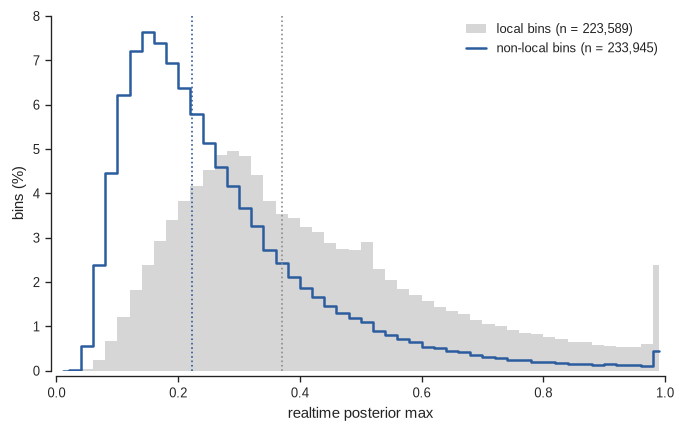

,n,median posterior max,% >= 0.3,% >= 0.5,% >= 0.7,% >= 0.9
bins,,,,,,
local,223589,0.371,64.986,30.185,12.615,4.623
"non-local, all",233945,0.223,31.133,9.456,3.046,0.946
"non-local, agree with offline",14380,0.301,50.389,18.616,7.038,2.796
"non-local, disagree",219565,0.218,29.871,8.856,2.785,0.825


posterior max separating right from wrong non-local bins: AUC 0.659 (0.5 = no separation, 1 = perfect)


In [18]:
edges = np.linspace(0, 1, 51)
ctr_  = (edges[:-1] + edges[1:]) / 2
local_bins = pairs.known.to_numpy() & ~rt_nl
nl_right, nl_wrong = rt_nl & agree, rt_nl & ~agree

def pct_hist(m):
    h, _ = np.histogram(pm[m], bins=edges)
    return 100 * h / h.sum()

fig, ax = plt.subplots(figsize=(5.6, 3.5))
ax.fill_between(ctr_, pct_hist(local_bins), step='mid', color=MUTED, alpha=0.35, lw=0,
                label=f'local bins (n = {local_bins.sum():,})')
ax.step(ctr_, pct_hist(rt_nl), where='mid', color=RT, label=f'non-local bins (n = {rt_nl.sum():,})')
for m, c in [(local_bins, MUTED), (rt_nl, RT)]:
    ax.axvline(np.median(pm[m]), color=c, lw=1, ls=':')
ax.set_xlim(0, 1); ax.set_ylim(0, None)
ax.set_xlabel('realtime posterior max'); ax.set_ylabel('bins (%)')
ax.legend(loc='upper right', fontsize=7.5)
show(fig, 'trust12_posterior_max_distributions')

rows = []
for lab, m in [('local', local_bins), ('non-local, all', rt_nl),
               ('non-local, agree with offline', nl_right), ('non-local, disagree', nl_wrong)]:
    rows.append({'bins': lab, 'n': int(m.sum()), 'median posterior max': np.median(pm[m]),
                 **{f'% >= {t:g}': 100 * (pm[m] >= t).mean() for t in (0.3, 0.5, 0.7, 0.9)}})
display(pd.DataFrame(rows).set_index('bins').round(3))
print(f'posterior max separating right from wrong non-local bins: AUC {auc(pm[rt_nl], agree[rt_nl]):.3f} '
      f'(0.5 = no separation, 1 = perfect)')

**Figure 12.** Distribution of realtime's posterior max for its non-local bins (line) and local bins (shaded);
0.02-wide bins, each distribution sums to 100%; dotted lines: medians. Numbers are from the blocked-hexes run (Oct 15).

**Takeaway.**

- **Non-local decodes are less confident than local ones:** median posterior max 0.22 against 0.37. Only 9.5% of
  non-local bins reach ≥ 0.5, against 30% of local bins.
- **Right non-local decodes are only a bit more confident than wrong ones** (table: median 0.30 vs 0.22; ≥ 0.5: 18.6%
  vs 8.9%), and the two overlap heavily (AUC 0.66).
- **The wrong ones vastly outnumber the right ones, about 15 to 1** (219,565 vs 14,380 bins). So even at ≥ 0.5, the kept
  non-local bins are about 2,700 right against 19,400 wrong, i.e. roughly 12% right. That is why no posterior-max
  threshold makes realtime's non-local content trustworthy (§4, §11).
- **A small pile-up at 1.0** among local bins: bins where the posterior has collapsed onto a single hex.

## 13 · False positives of realtime non-local stretches (offline as ground truth)

If the laser fired on every realtime non-local stretch, how many of those would be **false positives**, i.e. moments
when offline (the ground truth here) has no non-local stretch? Swept over the posterior-max threshold.

- **Unit:** one realtime non-local stretch (decode > 20 cm from the rat for > 20 ms; the parent intervals of §5).
- **Threshold:** a stretch is kept if its **peak** posterior max (its most confident bin) is ≥ t.
- **Match, timing only:** at least one bin of the stretch lies inside an offline non-local stretch.
- **Match, timing + place:** the same, and in at least half of those overlapping bins realtime's hex is within 1 hex of
  offline's `decode_hex_any`.
- **False positive** = a kept stretch with no match.
- **Chance:** the same stretches moved by half the session, with their decodes travelling with them. That keeps how
  many there are, how long they are and where they point, but breaks the timing link with offline.

Stretches are grouped by the rat's mean speed during the stretch. Bands: 95% CI (stretches resampled by 30 s chunk).

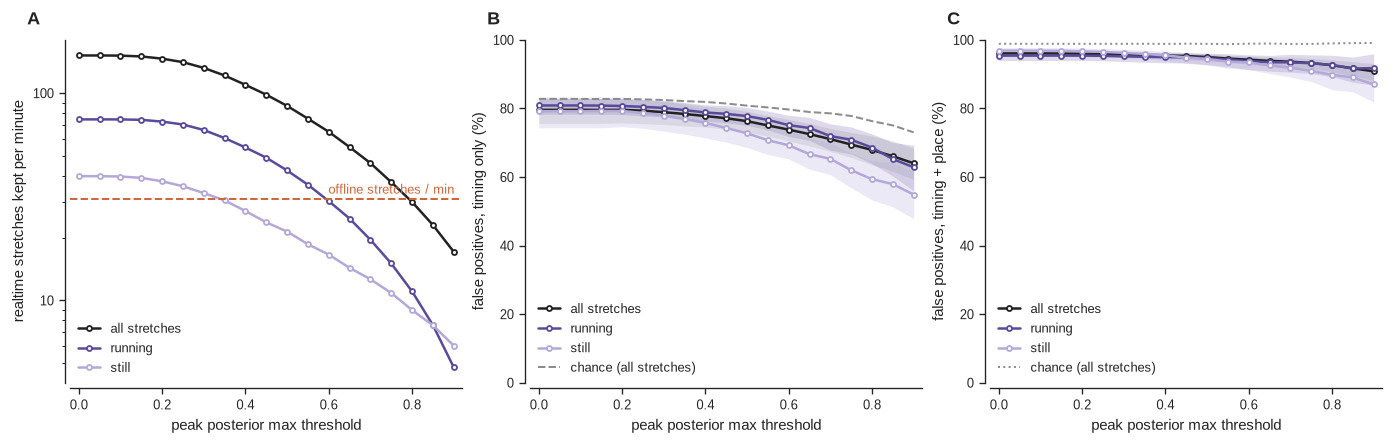

6,954 realtime non-local stretches (152/min) scored against 1,416 offline ones (31/min); all stretches:


,stretches kept / min,kept %,"false pos., timing %",chance %,"false pos., timing + place %",chance %
peak posterior max >=,,,,,,
0.0,152.0,100.0,79.6,82.8,96.0,98.8
0.2,146.7,96.5,79.6,82.8,96.0,98.9
0.3,132.4,87.1,78.9,82.4,95.7,98.8
0.4,109.7,72.2,77.8,81.9,95.5,98.8
0.5,86.8,57.1,76.3,80.8,95.0,98.8
0.6,65.1,42.8,73.8,79.7,94.2,98.9
0.7,46.0,30.3,71.1,78.6,93.6,98.8
0.8,29.9,19.7,67.9,76.3,92.6,99.0
0.9,17.2,11.3,64.0,73.0,90.8,99.1


In [19]:
rte, ofe = EV['realtime']['parent'], EV['offline']['parent']
rt_id = bin_membership(rte)                     # realtime stretch containing each bin (-1 = none)
of_id = bin_membership(ofe)                     # offline stretch containing each bin (-1 = none)
n_rt  = len(rte)
inn   = rt_id >= 0
peak  = np.full(n_rt, -np.inf)
np.maximum.at(peak, rt_id[inn], pm[inn])        # most confident bin of each stretch
spd_r = np.bincount(rt_id[inn], weights=pairs.speed.to_numpy()[inn], minlength=n_rt) / np.bincount(rt_id[inn], minlength=n_rt)
blk_r = blk[np.searchsorted(tb, rte.start_time.to_numpy())]

def matches(of_at, same):
    # per realtime stretch: timing match (some bin inside an offline stretch) and timing + place match
    ov  = np.bincount(rt_id[inn & (of_at >= 0)], minlength=n_rt)
    ovs = np.bincount(rt_id[inn & (of_at >= 0) & same], minlength=n_rt)
    return ov > 0, (ov > 0) & (ovs >= 0.5 * ov)

m_time, m_place = matches(of_id, agree)
shift_idx = (np.arange(len(tb)) + half) % len(tb)     # each realtime bin moved half a session later
d_c = hex_steps(pairs.rt_dec.to_numpy(), pairs.of_dec.to_numpy()[shift_idx])
c_time, c_place = matches(of_id[shift_idx], (d_c >= 0) & (d_c <= AGREE_TOL))

fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.6))
a0, a1, a2 = axes
for lab, m, c, ba in event_groups(spd_r):
    lab = 'all stretches' if lab == 'all events' else lab
    a0.plot(THRESH, [(m & (peak >= t)).sum() / dur_min for t in THRESH], color=c, marker='o', ms=3, mfc='white',
            mew=1.1, label=lab)
    for ax, mm in [(a1, m_time), (a2, m_place)]:
        cv = thr_curve(blk_r, lambda t: m & (peak >= t) & ~mm, lambda t: m & (peak >= t), min_n=30)
        ci_line(ax, cv.index, cv, c, label=lab, band_alpha=ba, ms=3)
a0.axhline(len(ofe) / dur_min, color=OF, lw=1.2, ls='--')
a0.annotate('offline stretches / min', xy=(0.98, len(ofe) / dur_min), xycoords=('axes fraction', 'data'),
            xytext=(0, 3), textcoords='offset points', ha='right', fontsize=7.5, color=OF)
a0.set_yscale('log'); a0.yaxis.set_major_formatter(PLAIN)
thr_axes(a0, 'realtime stretches kept per minute', ylim=None)
a0.legend(loc='lower left')
for ax, cm_, ls, yl in [(a1, c_time, '--', 'false positives, timing only (%)'),
                        (a2, c_place, ':', 'false positives, timing + place (%)')]:
    ch = [100 * (~cm_[peak >= t]).mean() if (peak >= t).sum() >= 30 else np.nan for t in THRESH]
    ax.plot(THRESH, ch, color=MUTED, ls=ls, lw=1.2, label='chance (all stretches)')
    thr_axes(ax, yl)
    ax.legend(loc='lower left')
for ax in axes:
    ax.set_xlabel('peak posterior max threshold')
letter(axes)
show(fig, 'trust13_false_positives')

rows = []
for t in [0, .2, .3, .4, .5, .6, .7, .8, .9]:
    k_ = peak >= t
    if k_.sum() == 0:
        continue
    rows.append({'peak posterior max >=': t, 'stretches kept / min': k_.sum() / dur_min, 'kept %': 100 * k_.mean(),
                 'false pos., timing %': 100 * (~m_time[k_]).mean(), 'chance %': 100 * (~c_time[k_]).mean(),
                 'false pos., timing + place %': 100 * (~m_place[k_]).mean(), 'chance  %': 100 * (~c_place[k_]).mean()})
print(f'{n_rt:,} realtime non-local stretches ({n_rt / dur_min:.0f}/min) scored against {len(ofe):,} offline ones '
      f'({len(ofe) / dur_min:.0f}/min); all stretches:')
display(pd.DataFrame(rows).set_index('peak posterior max >=').round(1))

**Figure 13.** Realtime non-local stretches kept by their **peak** posterior max, scored against offline's
non-local stretches, grouped by the rat's mean speed. **A**, Stretches kept per minute (log axis); dashed orange:
offline's rate. **B**, False positives on timing alone: kept stretches with no bin inside an offline non-local stretch.
**C**, False positives on timing + place: no overlap, or realtime within 1 hex of offline in fewer than half the
overlapping bins. Grey: chance (the same stretches moved by half the session). Bands: 95% CI. Numbers are from the
blocked-hexes run (Oct 15).

**Takeaway.**

- **Realtime has about 5× more non-local stretches than offline** (152 vs 31 a minute). It takes a peak threshold of
  about 0.8 to bring the number down to offline's rate.
- **Timing only, most are false positives:** 80% with no threshold (chance 83%), 76% at ≥ 0.5 (chance 81%), 64% at ≥ 0.9
  (chance 73%). Raising the threshold moves the false-positive rate only 3–9 points beyond what chance alone does.
  Stretches while the rat is still do a bit better (about 55% at ≥ 0.9).
- **Timing + place, almost all are false positives:** 96% with no threshold, 95% at ≥ 0.5 and 91% at ≥ 0.9 (chance about
  99% throughout). The true positives rise from 4% to 9%, which is 4–10× chance, but that is still only about 1 kept
  stretch in 11 at ≥ 0.9.
- **Why the chance line falls too:** a peak rule favours long stretches (more bins, more chances of one confident
  bin), and long stretches also overlap offline more often by luck. So read each curve against its own chance line,
  not against its value at t = 0.
- **For a trigger:** at ≥ 0.8 realtime fires about as often as offline has non-local stretches (30 a minute), but 68% of
  those triggers have no offline non-local stretch at all, and 93% don't match its content.

---
## Notes and caveats

- **One session.** Everything here is Toby 2025-03-16 session 07, a no-preload run. Thresholds that work here should
  be re-checked on other sessions (especially a preloaded run of the same recording) before they become an
  experimental condition.
- **Offline is a smoother**, so it has information realtime never has (future spikes). Some disagreement is expected
  by design, and §6 shows how much depends on the reference's own confidence.
- **Realtime's position is quantised** to hex centres (one hex ≈ 13 cm), plus a few cm of px→cm conversion error, so
  bins near the 20 cm line can flip between local and non-local.
- **The train/test split** alternates 2-minute chunks. Neighbouring chunks are not fully independent, so the held-out
  numbers are a little optimistic compared with a truly new session.
- The **tetrode count** in §9 is rebuilt from encoder records by timestamp, an approximation of exactly which spikes
  the decoder used in each bin.